# Latent UMAPs across models (per dataset, best model per row)

*One UMAP per `(model, dataset)` pair on the seven-dataset
integration registry, three colorings each
(species / cell-type / donor batch). The visual companion to
`07_baselines_master.ipynb`'s quantitative scorecard.*

## What this notebook is for

The integration scorecard in `07_baselines_master.ipynb` reduces each
`(model, dataset)` pair to a handful of scalars (kNN species purity,
label-transfer accuracy, silhouette-celltype, …). This notebook
complements that with the **picture** the scorecard summarizes:
a UMAP of each model's latent `z`, colored three ways so the
reader can read off mixing vs. structure qualitatively for every
method on every dataset.

The seven-row dataset registry is the same as in `04_*` / `07_*`.
Single-seed s42 per dataset, pointing at the *best* run per model
per `chimera/training/workflow-best.md`. Note: registry keys still
use the legacy `panc_*` typo for the Camex liver datasets — the
actual tissue is **liver**, and figure-facing labels say so.

Models covered (mirrors `MODEL_ORDER` in
`_baselines_master_builder.py`):
`PCA`, `scVI-sp`, `scVI-donor`, `scANVI`, `Harmony`, `sysVI`,
`Chimera`. 7 models × 7 datasets × 3 colorings = up to **147
figures**.

## What's cached

UMAP fits are **cached to disk** under
`chimera/notebooks/cache/chimera_umap/<ds_key>__<model_slug>__umap.npy`.
The first pass computes `sc.pp.neighbors` + `sc.tl.umap` for each
`(model, dataset)` pair (~30 s per ~10K cells, ~30 minutes for
all 49 pairs); every subsequent run loads the cached
`(n_cells, 2)` array and goes straight to plotting. This is what
lets the figure-styling cells be edited and re-run without
paying the embedding cost. Delete a cache file to force a
recompute, or call `compute_or_load_umap(ds_key, model,
force=True)`.

*Backwards compat:* the previous Chimera-only run wrote
`<ds>__umap.npy` (no model in the name); on first execution the
helper auto-renames any such legacy file to
`<ds>__chimera__umap.npy` so prior compute is not wasted.


## §0.1 — Imports and design system


In [1]:
from __future__ import annotations

import sys
import time
import warnings
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

# Notebook folder: $CHIMERA_ROOT/notebooks if set, else located from the working directory.
import os
NB_DIR = (Path(os.environ["CHIMERA_ROOT"]) / "notebooks" if os.environ.get("CHIMERA_ROOT")
          else Path.cwd() if (Path.cwd() / "_figure_design.py").exists()
          else Path.cwd() / "notebooks")
assert (NB_DIR / "_figure_design.py").exists(), f"no notebooks folder at {NB_DIR}; set CHIMERA_ROOT"
if str(NB_DIR) not in sys.path:
    sys.path.insert(0, str(NB_DIR))

import _figure_design as fd

fd.apply_design()

# Quiet scanpy: we want clean cell outputs — verbose=0 silences the
# "computing neighbors / umap…" prints; warnings module hides the
# numba/umap-learn deprecation chatter that bloats logs.
sc.settings.verbosity = 0
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="umap")


## §0.2 — Dataset + model registry (best run per (model, dataset))

Same seven `(tissue × species set)` rows as
`07_baselines_master.ipynb`'s `DATASETS`. For each dataset, the
Chimera best-known is taken from the `chimera_run` field; the six
baseline models follow `_baselines_master_builder.py`'s
`baseline_path(...)` convention. Single-seed (s42) per row.

| Registry key | Tissue | Pair | Chimera best run |
|---|---|---|---|
| `panc_hmonkey` | liver | H+Monkey | `iter90-150ep-s42` |
| `panc_hmouse`  | liver | H+Mouse  | `xds-hmouse-iter90-150ep-s42` |
| `panc_hzeb`    | liver | H+Zebrafish | `xds-hzeb-iter85-s42` |
| `panc_4sp`     | liver | 4-species | `xds-4sp-iter101-adv200-mmd100-fb10-200ep-s42` |
| `test_hmac`    | testis | H+Macaque | `testis-hmac-iter109-pclamp085-200ep-s42` |
| `test_hmouse`  | testis | H+Mouse | `testis-hmouse-iter111-pclamp-coc-200ep-s42` |
| `test_3sp`     | testis | 3-species | `testis-unified-iter115-pclamp-coc-100ep-s42` |

Baselines per dataset:

- **`PCA`**        — log-norm + HVG + PCA (`baselines_pca/<stem>/`)
- **`scVI-sp`**    — scVI with `species` as batch
  (`baselines_scvi/<stem>-s42-e100-nl10/`)
- **`scVI-donor`** — scVI with the donor batch key
  (`<stem>-s42-e100-nl10-bk_<donor>`)
- **`scANVI`**     — scANVI with `cell_type` labels + donor batch
  (`baselines_scanvi/<stem>-s42-bk_<donor>`)
- **`Harmony`**    — Harmony on PCA, donor batch
  (`baselines_harmony/<stem>-s42-bk_<donor>`)
- **`sysVI`**      — sysVI (scvi-tools experimental) with donor batch
  (`baselines_sysvi/<stem>-s42-bk_<donor>`)
- **`Chimera`**    — the canonical run from `DATASETS[*].chimera_run`

All baselines emit `n_latent=10` (PCA: 10 components); Chimera is
also 10. UMAP fits each method's `z` independently so the panels
are directly visually comparable.


In [2]:
REPO_ROOT = NB_DIR.parent
RUNS_ROOT = REPO_ROOT / "training" / "runs"
DATA_ROOT = REPO_ROOT / "data" / "processed"

CACHE_DIR = NB_DIR / "cache" / "chimera_umap"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

FIG_DIR = fd.set_figure_dir(NB_DIR / "figures" / "chimera_umap")
print(f"figures will be written to: {FIG_DIR}")
print(f"UMAP cache directory:       {CACHE_DIR}")

# Registry keys retain the legacy `panc_*` prefix (typo — the tissue is
# liver). Figure-facing `label` strings say "liver" so the rendered
# panels are paper-correct.
DATASETS = {
    "panc_hmonkey":  {"adata_stem": "camex_human_monkey",
                      "label": "liver H+Monkey",   "tissue": "liver",
                      "donor_batch_key": "batch",
                      "chimera_run": "iter90-150ep-s42"},
    "panc_hmouse":   {"adata_stem": "camex_human_mouse",
                      "label": "liver H+Mouse",    "tissue": "liver",
                      "donor_batch_key": "batch",
                      "chimera_run": "xds-hmouse-iter90-150ep-s42"},
    "panc_hzeb":     {"adata_stem": "camex_human_zebrafish",
                      "label": "liver H+Zeb",      "tissue": "liver",
                      "donor_batch_key": "batch",
                      "chimera_run": "xds-hzeb-iter85-s42"},
    "panc_4sp":      {"adata_stem": "camex_pancreas_unified",
                      "label": "liver 4-sp",       "tissue": "liver",
                      "donor_batch_key": "batch",
                      "chimera_run": "xds-4sp-iter101-adv200-mmd100-fb10-200ep-s42"},
    "test_hmac":     {"adata_stem": "camex_testis_human_macaque",
                      "label": "testis H+Mac",     "tissue": "testis",
                      "donor_batch_key": "sample_batch",
                      "chimera_run": "testis-hmac-iter109-pclamp085-200ep-s42"},
    "test_hmouse":   {"adata_stem": "camex_testis_human_mouse",
                      "label": "testis H+Mouse",   "tissue": "testis",
                      "donor_batch_key": "sample_batch",
                      "chimera_run": "testis-hmouse-iter111-pclamp-coc-200ep-s42"},
    "test_3sp":      {"adata_stem": "camex_testis_unified",
                      "label": "testis 3-sp",      "tissue": "testis",
                      "donor_batch_key": "sample_batch",
                      "chimera_run": "testis-unified-iter115-pclamp-coc-100ep-s42"},
}
DATASET_ORDER = list(DATASETS)

# Sanity: every registry row has a final_state.npz (Chimera z) and an h5ad.
print("\ndataset coverage check:")
for k, info in DATASETS.items():
    zp = RUNS_ROOT / info["chimera_run"] / "final_state.npz"
    ap = DATA_ROOT / f"{info['adata_stem']}.h5ad"
    print(f"  {info['label']:20s}  z:{'OK' if zp.exists() else 'MISSING':7s}"
          f"  adata:{'OK' if ap.exists() else 'MISSING'}")


figures will be written to: /Users/kemalinecik/git_nosync/master_chimera/chimera/notebooks/figures/chimera_umap
UMAP cache directory:       /Users/kemalinecik/git_nosync/master_chimera/chimera/notebooks/cache/chimera_umap

dataset coverage check:
  liver H+Monkey        z:OK       adata:OK
  liver H+Mouse         z:OK       adata:OK
  liver H+Zeb           z:OK       adata:OK
  liver 4-sp            z:OK       adata:OK
  testis H+Mac          z:OK       adata:OK
  testis H+Mouse        z:OK       adata:OK
  testis 3-sp           z:OK       adata:OK


In [3]:
# Model registry — same MODEL_ORDER as `07_baselines_master.ipynb`'s
# `_baselines_master_builder.py`, and the same `baseline_path(...)`
# convention so notebook 07 and 08 read the *same* run directories.
MODEL_ORDER = ["PCA", "scVI-sp", "scVI-donor", "scANVI", "Harmony", "sysVI", "Chimera"]

# Filename-safe slug per model (used in cache + figure names).
MODEL_SLUG = {
    "PCA":        "pca",
    "scVI-sp":    "scvi_sp",
    "scVI-donor": "scvi_donor",
    "scANVI":     "scanvi",
    "Harmony":    "harmony",
    "sysVI":      "sysvi",
    "Chimera":    "chimera",
}


def baseline_path(model: str, ds_key: str) -> Path | None:
    '''Resolve the run directory for one (model, dataset) pair. Mirrors
    `_baselines_master_builder.py`.'''
    info = DATASETS[ds_key]
    stem = info["adata_stem"]
    donor_bk = info["donor_batch_key"]
    if model == "PCA":
        return RUNS_ROOT / "baselines_pca" / stem
    if model == "scVI-sp":
        return RUNS_ROOT / "baselines_scvi" / f"{stem}-s42-e100-nl10"
    if model == "scVI-donor":
        return RUNS_ROOT / "baselines_scvi" / f"{stem}-s42-e100-nl10-bk_{donor_bk}"
    if model == "scANVI":
        return RUNS_ROOT / "baselines_scanvi" / f"{stem}-s42-bk_{donor_bk}"
    if model == "Harmony":
        return RUNS_ROOT / "baselines_harmony" / f"{stem}-s42-bk_{donor_bk}"
    if model == "sysVI":
        return RUNS_ROOT / "baselines_sysvi" / f"{stem}-s42-bk_{donor_bk}"
    if model == "Chimera":
        return RUNS_ROOT / info["chimera_run"]
    return None


def load_z(model: str, ds_key: str) -> np.ndarray:
    '''Per-cell latent for `(model, dataset)`. Chimera reads
    `final_state.npz`; baselines read `z_mean.npy`.'''
    p = baseline_path(model, ds_key)
    if model == "Chimera":
        fs = dict(np.load(p / "final_state.npz", allow_pickle=False))
        return np.asarray(fs["z_mean"])
    return np.load(p / "z_mean.npy")


# Coverage matrix: which (model, dataset) pairs have a usable run on disk?
print("\nmodel × dataset coverage (✓ = z available):")
print(f"  {'dataset':22s}  " + "  ".join(f"{m:>10s}" for m in MODEL_ORDER))
READY: dict[tuple[str, str], bool] = {}
for k in DATASET_ORDER:
    cells_row = []
    for m in MODEL_ORDER:
        p = baseline_path(m, k)
        ok = (p is not None) and p.exists() and (
            (p / "z_mean.npy").exists() or (p / "final_state.npz").exists()
        )
        READY[(k, m)] = bool(ok)
        cells_row.append("✓" if ok else "—")
    print(f"  {DATASETS[k]['label']:22s}  " + "  ".join(f"{c:>10s}" for c in cells_row))
n_ready = sum(READY.values())
print(f"\n{n_ready}/{len(DATASET_ORDER) * len(MODEL_ORDER)} (model, dataset) pairs ready.")



model × dataset coverage (✓ = z available):
  dataset                        PCA     scVI-sp  scVI-donor      scANVI     Harmony       sysVI     Chimera
  liver H+Monkey                   ✓           ✓           ✓           ✓           ✓           ✓           ✓
  liver H+Mouse                    ✓           ✓           ✓           ✓           ✓           ✓           ✓
  liver H+Zeb                      ✓           ✓           ✓           ✓           ✓           ✓           ✓
  liver 4-sp                       ✓           ✓           ✓           ✓           ✓           ✓           ✓
  testis H+Mac                     ✓           ✓           ✓           ✓           ✓           ✓           ✓
  testis H+Mouse                   ✓           ✓           ✓           ✓           ✓           ✓           ✓
  testis 3-sp                      ✓           ✓           ✓           ✓           ✓           ✓           ✓

49/49 (model, dataset) pairs ready.


## §0.3 — UMAP compute helper (cached, per (model, dataset))

The single load-bearing function in this notebook. For each
`(dataset, model)` pair:

1. Load the model's `z` via `load_z(model, ds_key)` — Chimera
   reads `final_state.npz`; baselines read `z_mean.npy`.
2. Build a thin AnnData (X is a 1-column zero placeholder so
   scanpy doesn't complain; the latent goes into
   `obsm['X_latent']`).
3. Run `sc.pp.neighbors(use_rep='X_latent', n_neighbors=15,
   random_state=0)` and `sc.tl.umap(min_dist=0.3,
   random_state=0)`. Both calls fix `random_state` for
   reproducibility — the cached coords are deterministic given
   the same `z`.
4. Cache the resulting `(n_cells, 2)` UMAP array to
   `cache/chimera_umap/<ds_key>__<model_slug>__umap.npy`.

Re-running the cell after the cache is populated reads each
`.npy` (millisecond-cheap) so the figure cells below can be
edited and re-rendered without paying the kNN + UMAP cost. To
force a recompute for one pair, pass `force=True` or delete that
cache file.

*Legacy cache migration:* the previous Chimera-only iteration of
this notebook wrote `<ds>__umap.npy` (no model in the filename).
On first execution the helper renames any such file to
`<ds>__chimera__umap.npy` so prior compute is reused.


In [4]:
UMAP_KW = dict(
    n_neighbors=15,
    min_dist=0.3,
    random_state=0,
)


# Cell-type column: prefer `cell_ontology_class` (the standardized
# vocabulary used in the testis cell-type-conditional MMD recipe
# per `workflow-best.md`); fall back to `cell_type` if missing.
def _resolve_celltype_col(obs: pd.DataFrame) -> str:
    for cand in ("cell_ontology_class", "cell_type"):
        if cand in obs.columns:
            return cand
    raise KeyError(
        f"no cell-type column found in obs (looked for "
        f"cell_ontology_class, cell_type); columns: {list(obs.columns)}"
    )


def _read_obs(ds_key: str) -> tuple[pd.DataFrame, str]:
    '''Return (obs DataFrame with [species, cell_type_col, batch_col],
    cell_type_col_name). Backed read — cheap; X is not loaded.'''
    info = DATASETS[ds_key]
    a = ad.read_h5ad(DATA_ROOT / f"{info['adata_stem']}.h5ad", backed="r")
    ct_col = _resolve_celltype_col(a.obs)
    cols = ["species", ct_col, info["donor_batch_key"]]
    # Materialize as ordinary DataFrame so categorical levels survive.
    obs = a.obs[cols].copy()
    a.file.close()
    return obs, ct_col


def compute_or_load_umap(
    ds_key: str, model: str, *, force: bool = False,
) -> np.ndarray:
    '''(n_cells, 2) UMAP coords for one (dataset, model) pair. Cached.'''
    slug = MODEL_SLUG[model]
    cache_path = CACHE_DIR / f"{ds_key}__{slug}__umap.npy"
    # Backwards compat: a previous Chimera-only run cached as
    # `<ds>__umap.npy`. Promote it to the new naming on first sight.
    if model == "Chimera" and not cache_path.exists():
        legacy = CACHE_DIR / f"{ds_key}__umap.npy"
        if legacy.exists() and not force:
            legacy.rename(cache_path)
            print(f"  {ds_key:14s}  {model:10s}  migrated legacy cache → "
                  f"{cache_path.name}")
    if cache_path.exists() and not force:
        xy = np.load(cache_path)
        print(f"  {ds_key:14s}  {model:10s}  cached  ({xy.shape[0]} cells)")
        return xy
    z = load_z(model, ds_key)
    adata_thin = ad.AnnData(
        X=np.zeros((z.shape[0], 1), dtype=np.float32),
        obs=pd.DataFrame(index=pd.RangeIndex(z.shape[0]).astype(str)),
    )
    adata_thin.obsm["X_latent"] = z.astype(np.float32)
    t0 = time.time()
    sc.pp.neighbors(adata_thin, use_rep="X_latent",
                    n_neighbors=UMAP_KW["n_neighbors"],
                    random_state=UMAP_KW["random_state"])
    sc.tl.umap(adata_thin,
               min_dist=UMAP_KW["min_dist"],
               random_state=UMAP_KW["random_state"])
    xy = np.asarray(adata_thin.obsm["X_umap"], dtype=np.float32)
    np.save(cache_path, xy)
    print(f"  {ds_key:14s}  {model:10s}  computed in {time.time()-t0:5.1f}s  "
          f"({xy.shape[0]} cells)  → {cache_path.name}")
    return xy


# First pass: compute (or load) the UMAP for every (dataset, model)
# pair flagged READY in §0.2. UMAPS is keyed by (ds_key, model) so
# downstream cells look up coords by pair without re-reading the cache.
print("UMAPs (cached, neighbors=15, min_dist=0.3, random_state=0):")
UMAPS: dict[tuple[str, str], np.ndarray] = {}
for k in DATASET_ORDER:
    for m in MODEL_ORDER:
        if not READY[(k, m)]:
            print(f"  {k:14s}  {m:10s}  skip — run not on disk")
            continue
        UMAPS[(k, m)] = compute_or_load_umap(k, m)


UMAPs (cached, neighbors=15, min_dist=0.3, random_state=0):
  panc_hmonkey    PCA         cached  (12608 cells)
  panc_hmonkey    scVI-sp     cached  (12608 cells)
  panc_hmonkey    scVI-donor  cached  (12608 cells)
  panc_hmonkey    scANVI      cached  (12608 cells)
  panc_hmonkey    Harmony     cached  (12608 cells)
  panc_hmonkey    sysVI       cached  (12608 cells)
  panc_hmonkey    Chimera     cached  (12608 cells)
  panc_hmouse     PCA         cached  (8091 cells)
  panc_hmouse     scVI-sp     cached  (8091 cells)
  panc_hmouse     scVI-donor  cached  (8091 cells)
  panc_hmouse     scANVI      cached  (8091 cells)
  panc_hmouse     Harmony     cached  (8091 cells)
  panc_hmouse     sysVI       cached  (8091 cells)
  panc_hmouse     Chimera     cached  (8091 cells)
  panc_hzeb       PCA         cached  (9655 cells)
  panc_hzeb       scVI-sp     cached  (9655 cells)
  panc_hzeb       scVI-donor  cached  (9655 cells)
  panc_hzeb       scANVI      cached  (9655 cells)
  panc_hzeb    

## §0.4 — Plot helpers

A single categorical-scatter routine, parametrized by which obs
column to color by. The visual contract:

| Property | Setting |
|---|---|
| figsize | `(4.4, 3.8)` (matches the 05_esm UMAP panels) |
| marker | `s=2.5, alpha=0.85, linewidths=0, rasterized=True` |
| spines / ticks | hidden (UMAP axes are interpretation-free) |
| legend | off-axis to the right, **single column**; species in evolutionary order; cell-type / batch by population size |
| output | one PDF + PNG per panel under `figures/chimera_umap/` |

The species panel uses the project-wide
[`SPECIES_PALETTE`](_figure_design.py); cell-type and batch
panels use a colorblind-friendly Okabe-Ito-extended palette
(large enough to handle ≤ 12 categories without recycling on
any registry row).


In [5]:
SCATTER_KW = dict(s=2.5, alpha=0.85, linewidths=0, rasterized=True)

# Okabe-Ito + 4 extras = 12 distinct hues, colorblind-aware.
PALETTE_BIG = [
    "#0072B2", "#D55E00", "#009E73", "#CC79A7",
    "#E69F00", "#56B4E9", "#F0E442", "#999999",
    "#7B0099", "#0F8000", "#C45A00", "#5C3317",
]


def _categorical_colors(values: np.ndarray, *, sort_key=None) -> tuple[list[str], dict[str, str]]:
    '''Return (categories_in_order, color_map). `sort_key` reorders the
    categories before color assignment.'''
    cats = pd.Series(values).dropna().unique().tolist()
    if sort_key is not None:
        cats = sorted(cats, key=sort_key)
    else:
        # Default: by descending population size.
        counts = pd.Series(values).value_counts()
        cats = list(counts.index)
    cmap = {c: PALETTE_BIG[i % len(PALETTE_BIG)] for i, c in enumerate(cats)}
    return cats, cmap


def umap_panel(
    xy: np.ndarray,
    labels: np.ndarray,
    *,
    title: str,
    save_name: str,
    color_map: dict[str, str] | None = None,
    category_order: list[str] | None = None,
    legend_ncol: int = 1,
) -> None:
    '''Single-panel UMAP scatter colored by a categorical label.'''
    fig, ax = fd.make_axes(figsize=(4.4, 3.8))
    ax.set_xlabel("UMAP 1"); ax.set_ylabel("UMAP 2")
    ax.set_xticks([]); ax.set_yticks([])
    for s in ("top", "right", "bottom", "left"):
        ax.spines[s].set_visible(False)

    if category_order is None or color_map is None:
        order, color_map = _categorical_colors(labels)
    else:
        order = category_order

    # Draw NaN / "other" cells as background gray first so categorical
    # cells overplot them.
    is_nan = pd.isna(labels)
    if is_nan.any():
        ax.scatter(xy[is_nan, 0], xy[is_nan, 1], color="#dddddd",
                   **SCATTER_KW)

    for cat in order:
        m = (labels == cat) & ~is_nan
        n = int(m.sum())
        if n == 0:
            continue
        ax.scatter(xy[m, 0], xy[m, 1], color=color_map[cat],
                   label=f"{cat}  ($n${n})", **SCATTER_KW)

    # Legend: off-axis right, frameless, small.
    ax.legend(
        loc="center left", bbox_to_anchor=(1.02, 0.5),
        frameon=False, fontsize=6.5, handlelength=0.8,
        handletextpad=0.4, borderpad=0.2,
        ncol=legend_ncol, markerscale=2.5,
    )
    # Title sits *above* the axes so it never overlaps data. Left-aligned
    # to match the figure-design "no centered titles" preference; small
    # mid-gray to stay subordinate to the data.
    ax.set_title(title, loc="left", fontsize=8, color="#444444", pad=8)
    fd.save_figure(fig, save_name)
    plt.show()


print("plot helpers ready.")


plot helpers ready.


# §A — Per-(model, dataset) latent UMAPs

For each registry row × every model with a run on disk, three
figures: colored by **species**, by **cell type**
(`cell_ontology_class` where available, else `cell_type`), and
by **donor batch** (`batch` for liver, `sample_batch` for
testis). The species panel is the integration diagnostic —
chunks of pure color = species leakage; well-mixed = good
integration. The cell-type panel is the structure diagnostic —
distinct labeled clusters = preserved biology; salt-and-pepper
= over-integration. The batch panel is the confound diagnostic
— donor structure should be subordinate to species and
cell-type structure.

Models are rendered in the order
`PCA → scVI-sp → scVI-donor → scANVI → Harmony → sysVI →
Chimera`, mirroring `MODEL_ORDER` in
`_baselines_master_builder.py`. Reading top-to-bottom in this
section therefore reproduces the canonical model ordering used
in the integration scorecard.



=== liver H+Monkey ===

--- liver H+Monkey  ·  PCA  (12608 cells, z→UMAP cached) ---


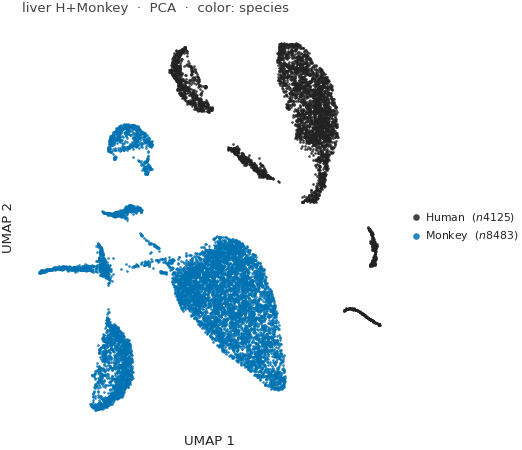

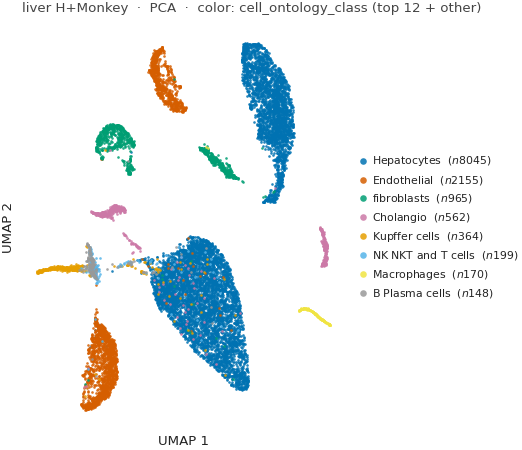

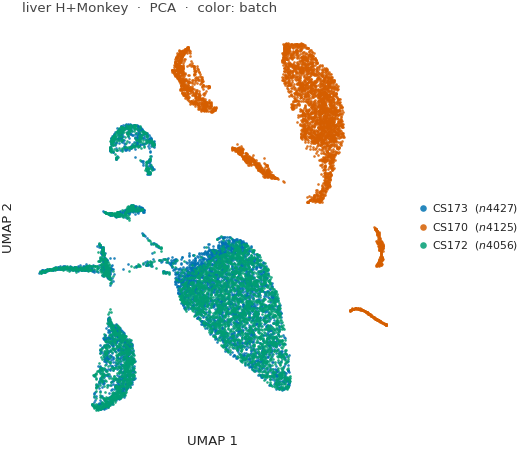


--- liver H+Monkey  ·  scVI-sp  (12608 cells, z→UMAP cached) ---


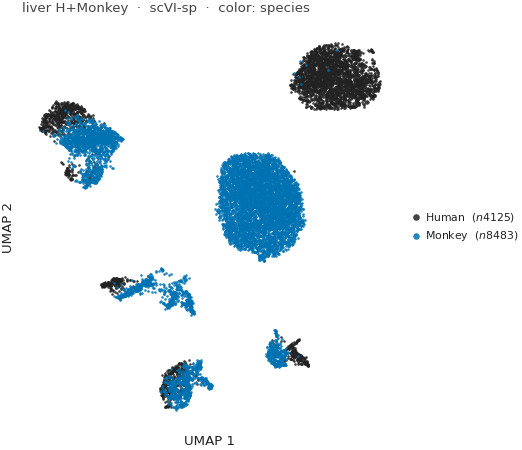

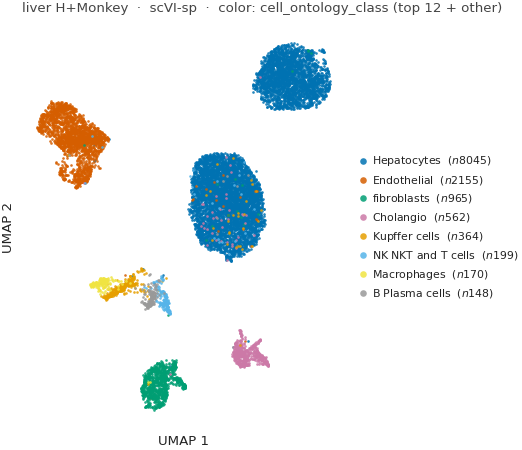

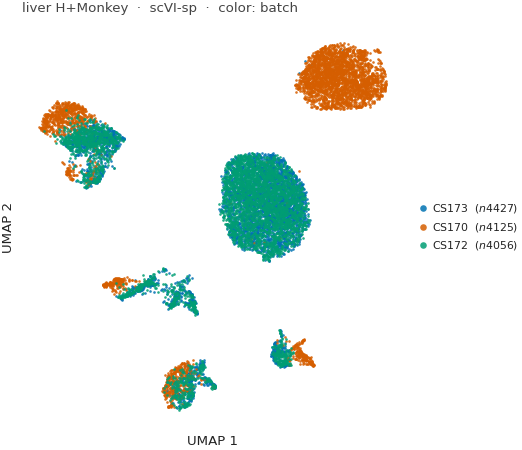


--- liver H+Monkey  ·  scVI-donor  (12608 cells, z→UMAP cached) ---


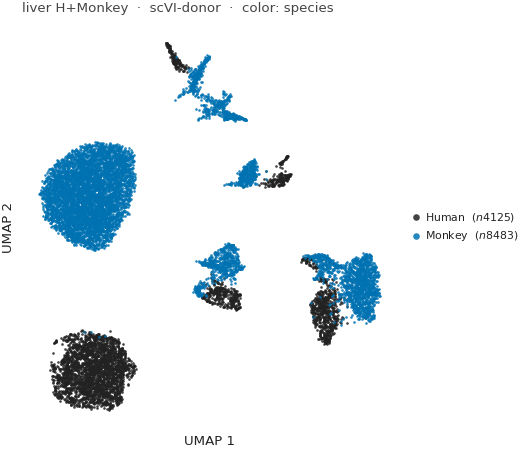

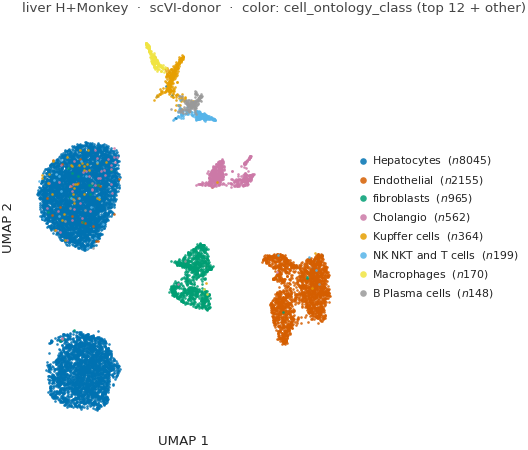

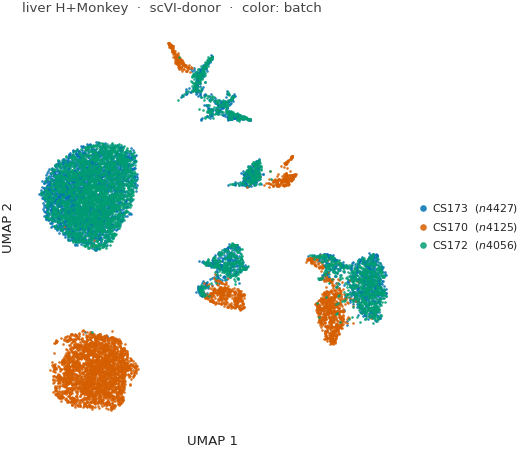


--- liver H+Monkey  ·  scANVI  (12608 cells, z→UMAP cached) ---


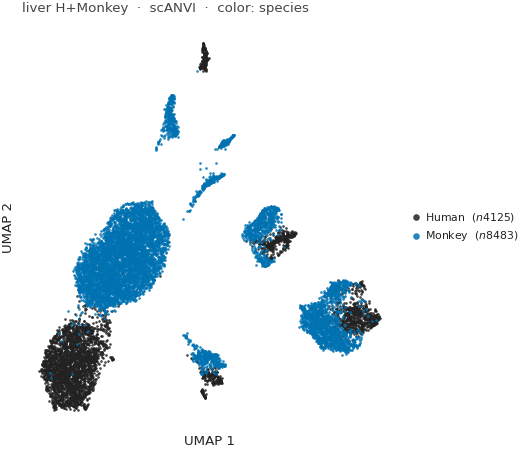

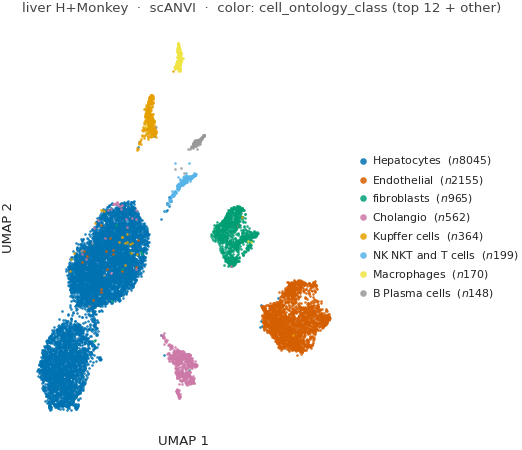

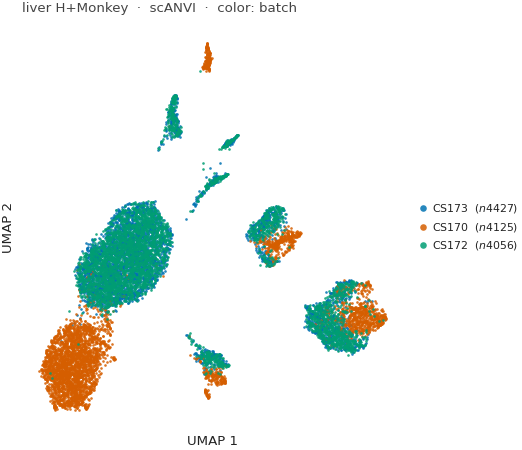


--- liver H+Monkey  ·  Harmony  (12608 cells, z→UMAP cached) ---


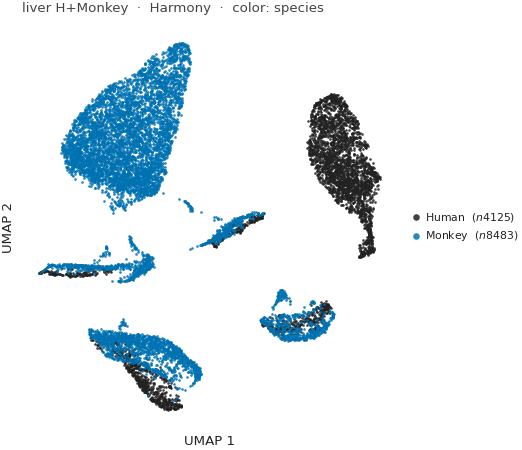

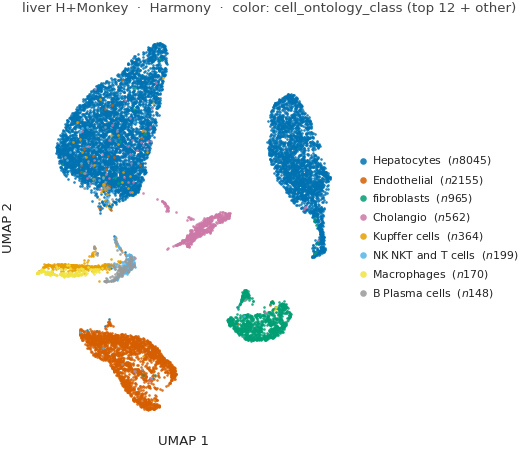

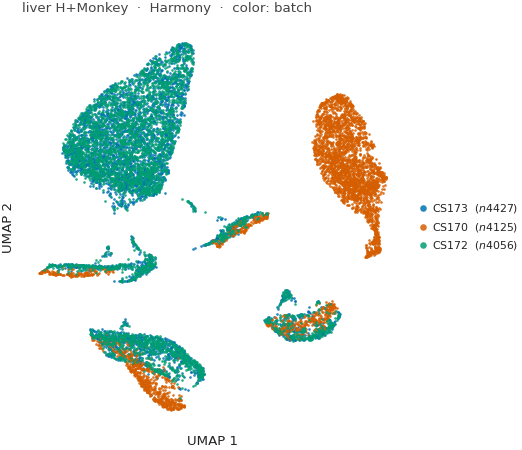


--- liver H+Monkey  ·  sysVI  (12608 cells, z→UMAP cached) ---


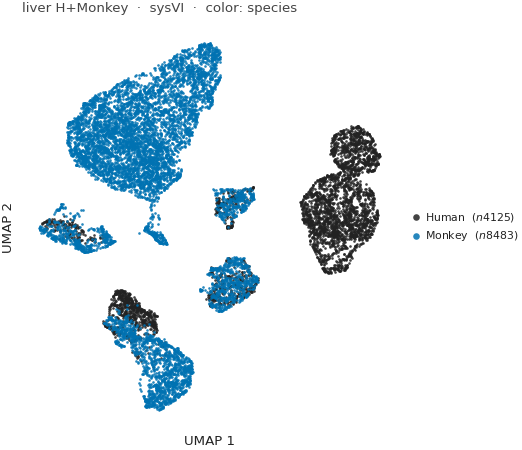

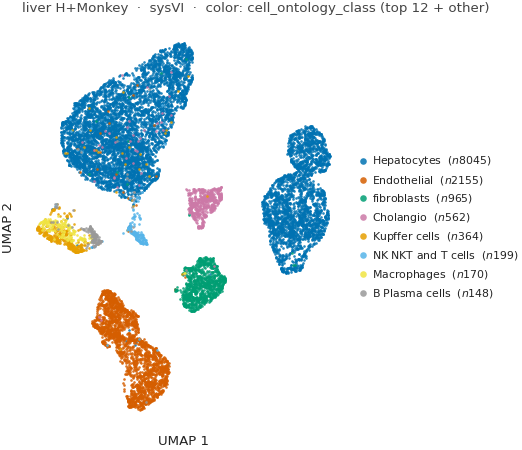

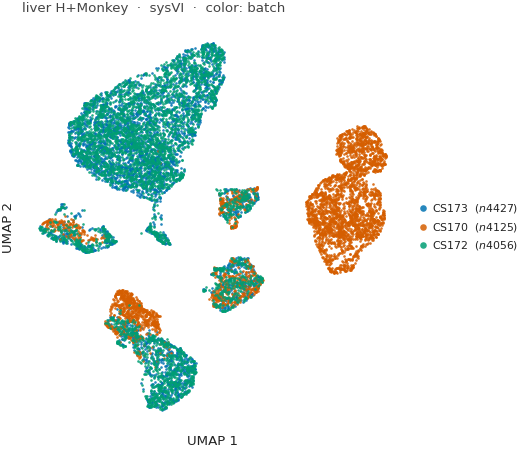


--- liver H+Monkey  ·  Chimera  (12608 cells, z→UMAP cached) ---


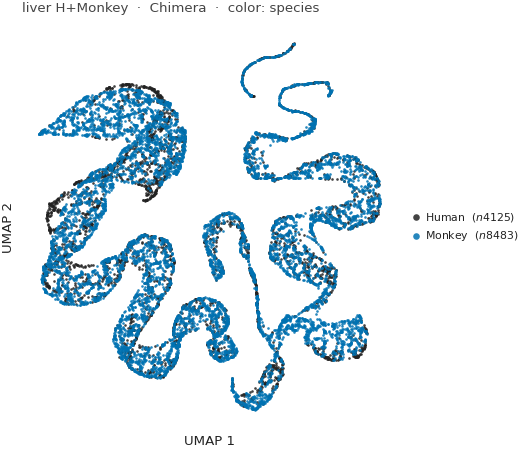

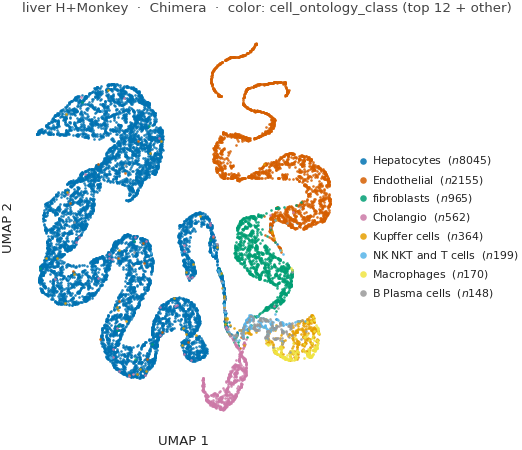

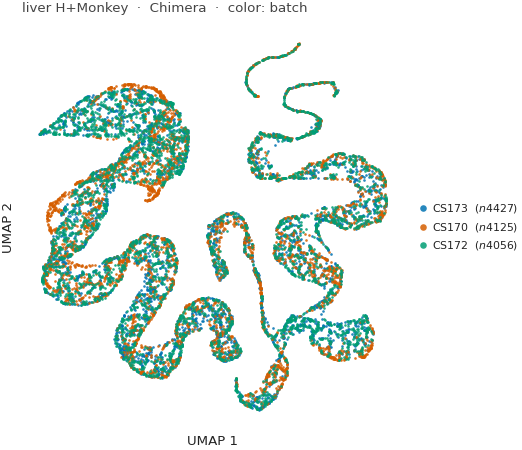


=== liver H+Mouse ===

--- liver H+Mouse  ·  PCA  (8091 cells, z→UMAP cached) ---


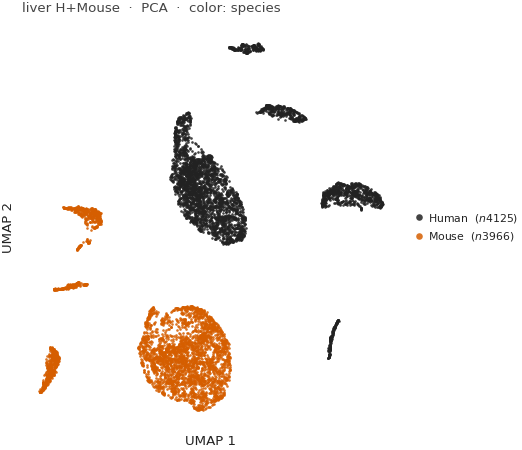

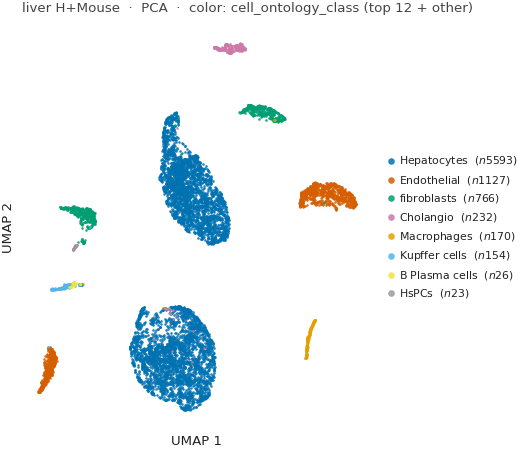

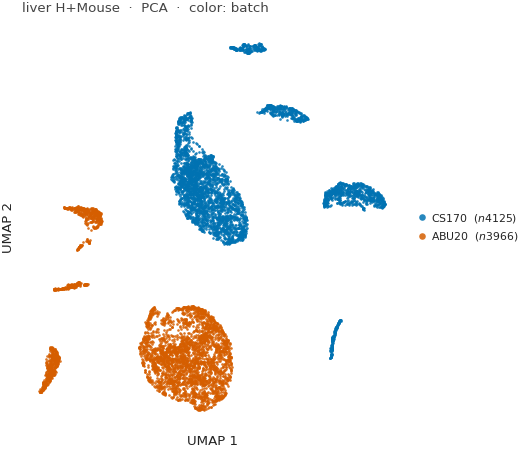


--- liver H+Mouse  ·  scVI-sp  (8091 cells, z→UMAP cached) ---


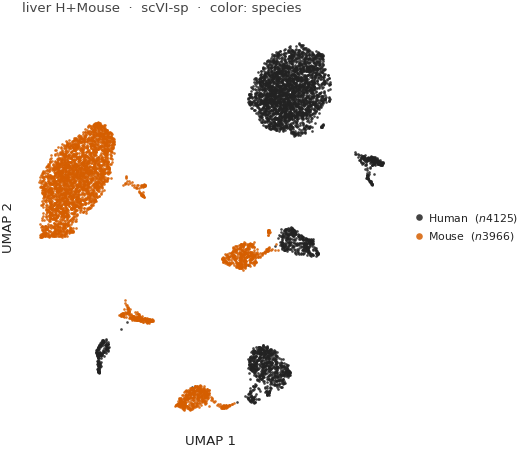

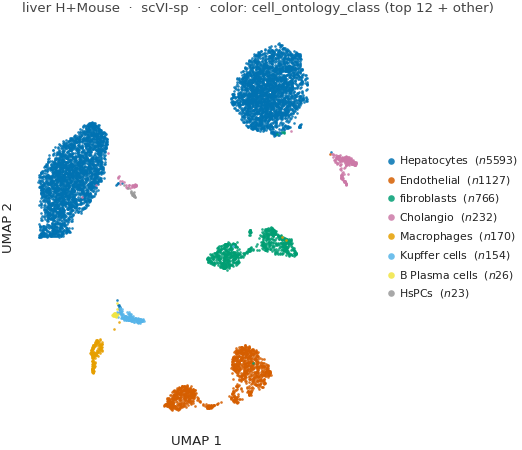

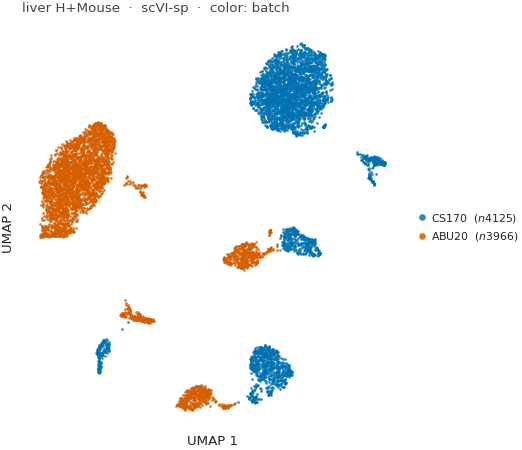


--- liver H+Mouse  ·  scVI-donor  (8091 cells, z→UMAP cached) ---


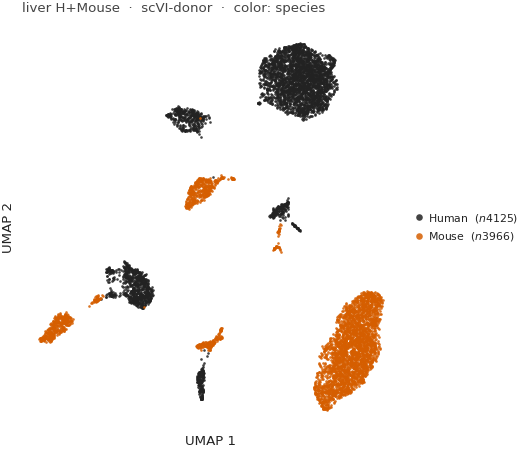

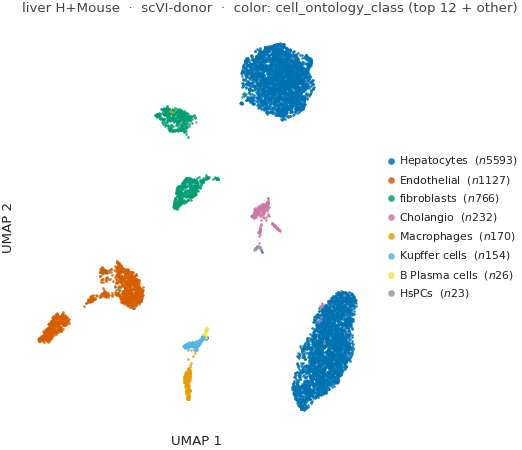

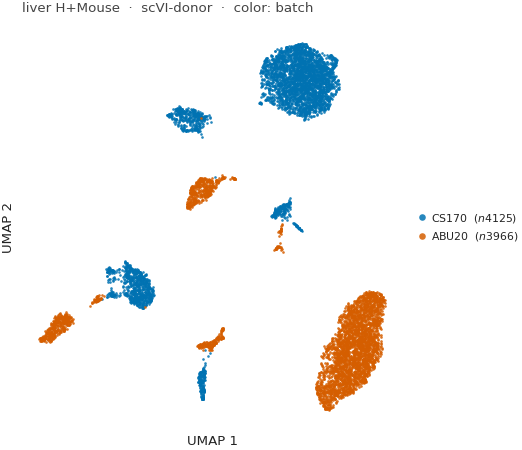


--- liver H+Mouse  ·  scANVI  (8091 cells, z→UMAP cached) ---


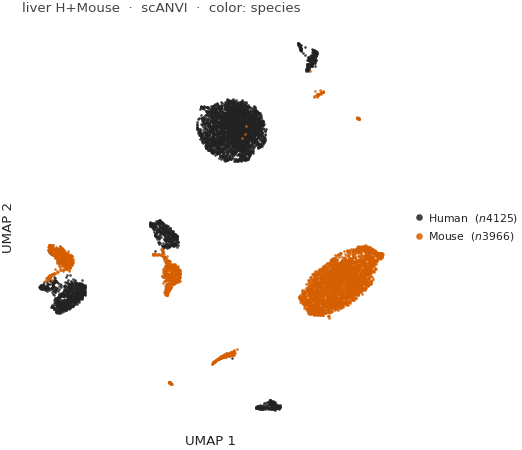

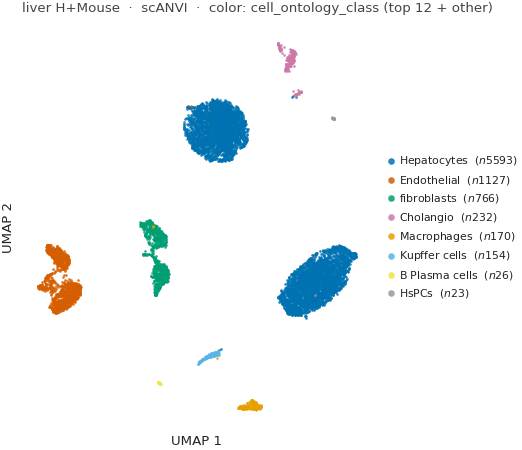

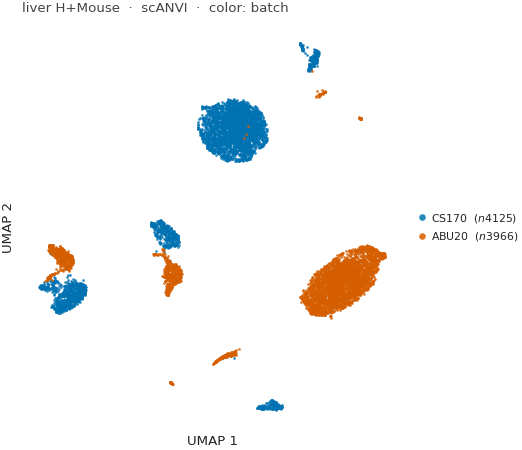


--- liver H+Mouse  ·  Harmony  (8091 cells, z→UMAP cached) ---


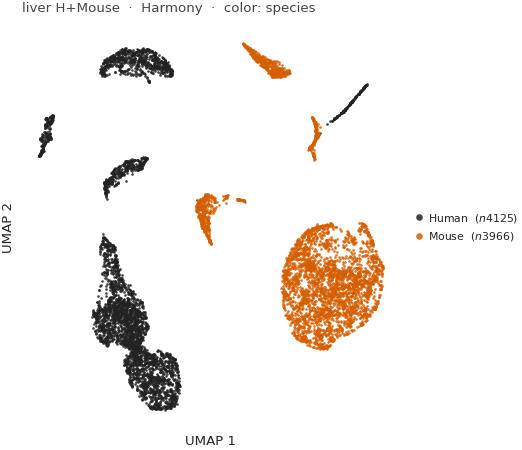

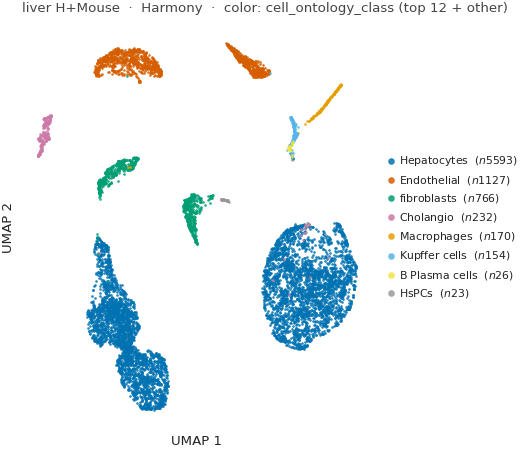

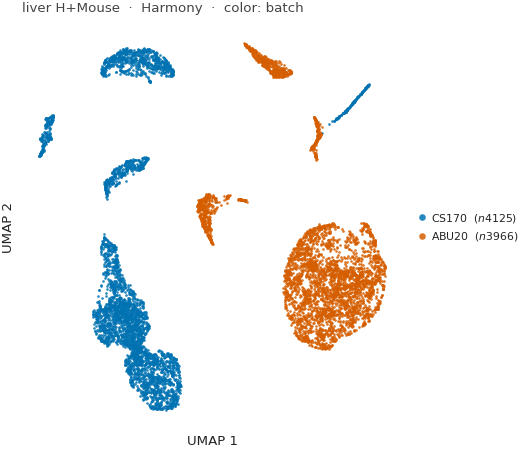


--- liver H+Mouse  ·  sysVI  (8091 cells, z→UMAP cached) ---


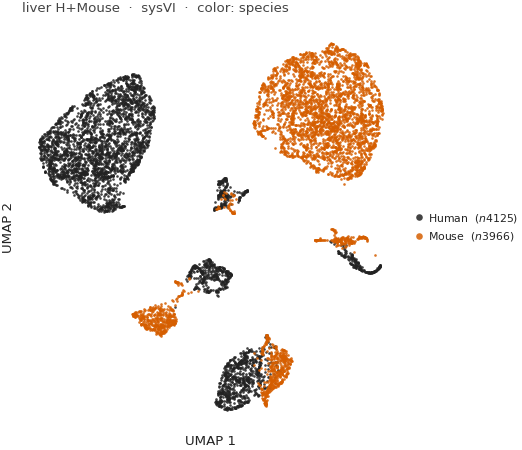

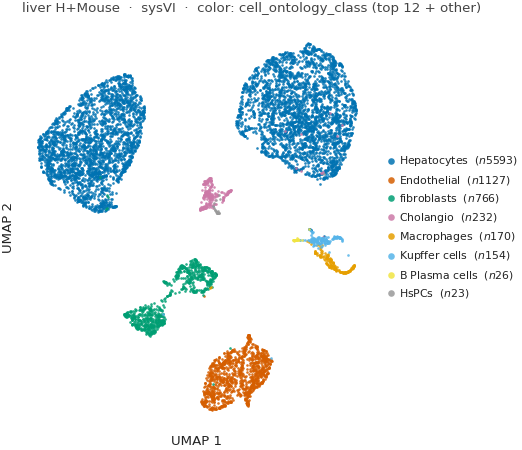

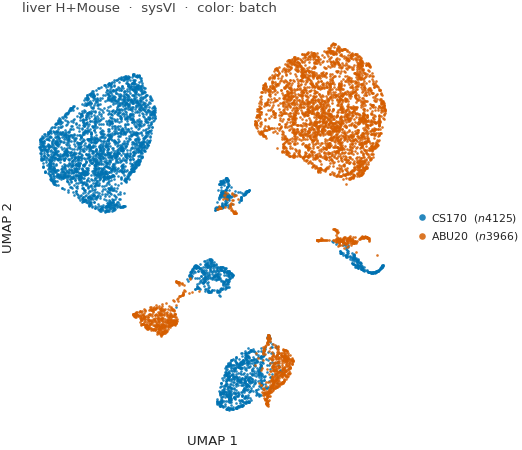


--- liver H+Mouse  ·  Chimera  (8091 cells, z→UMAP cached) ---


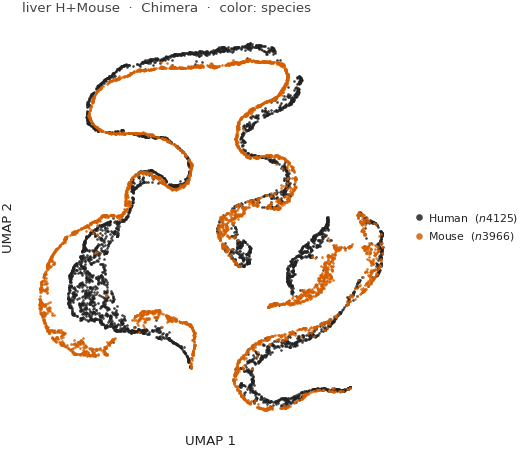

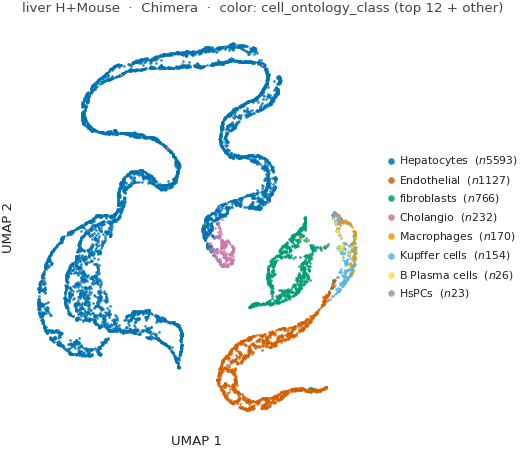

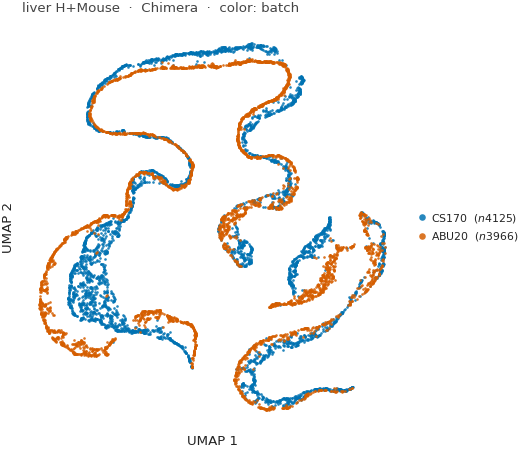


=== liver H+Zeb ===

--- liver H+Zeb  ·  PCA  (9655 cells, z→UMAP cached) ---


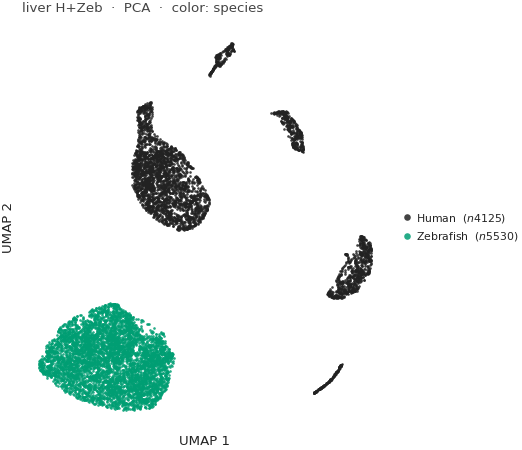

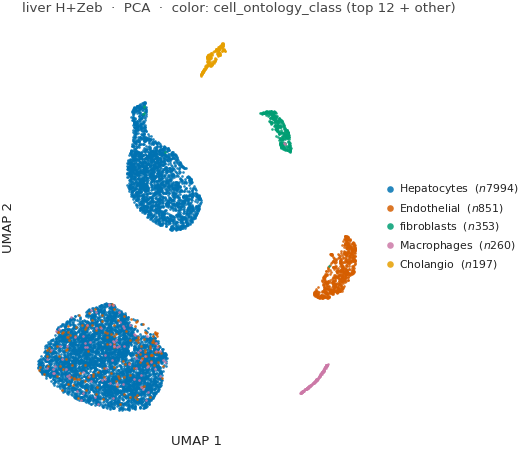

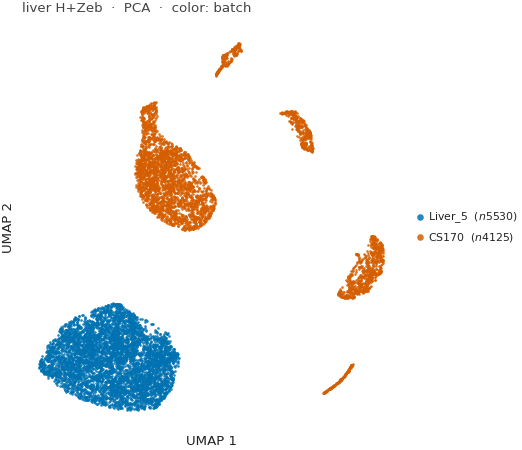


--- liver H+Zeb  ·  scVI-sp  (9655 cells, z→UMAP cached) ---


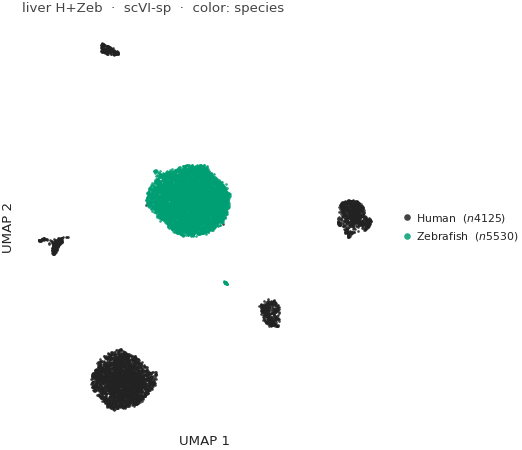

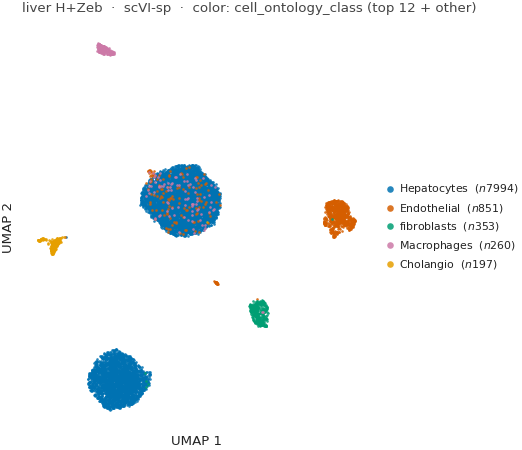

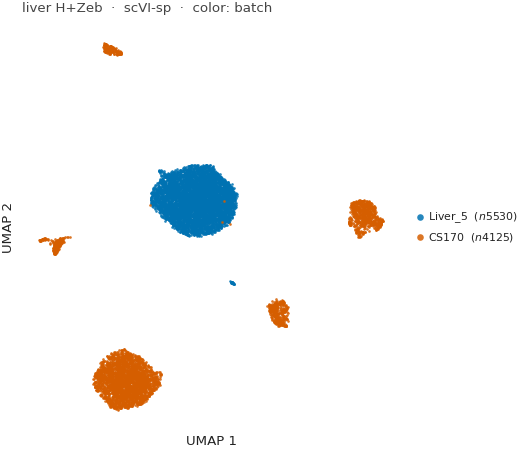


--- liver H+Zeb  ·  scVI-donor  (9655 cells, z→UMAP cached) ---


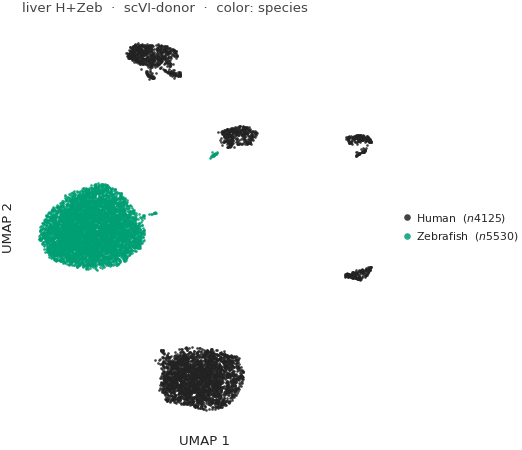

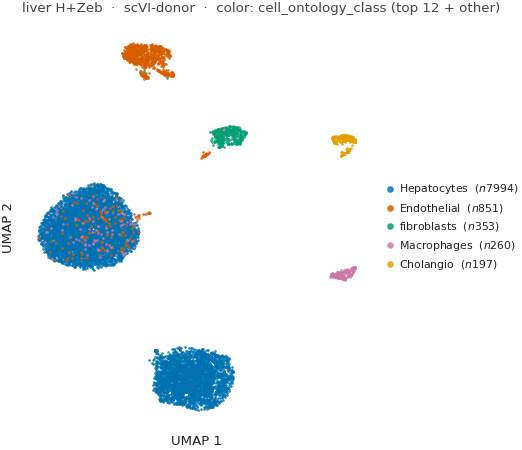

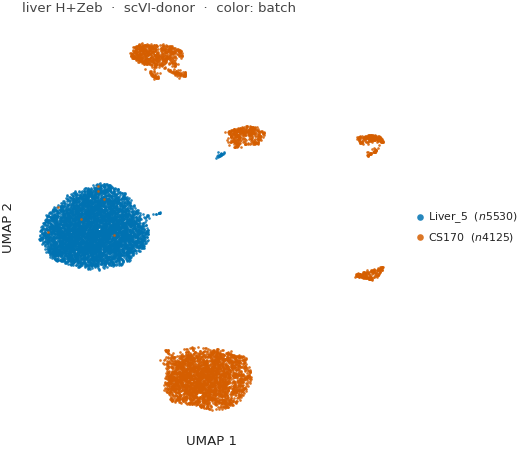


--- liver H+Zeb  ·  scANVI  (9655 cells, z→UMAP cached) ---


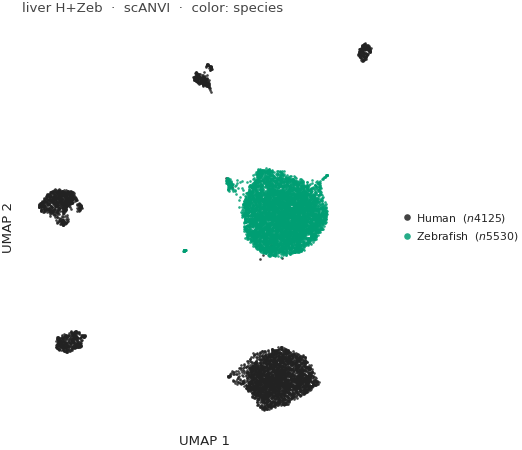

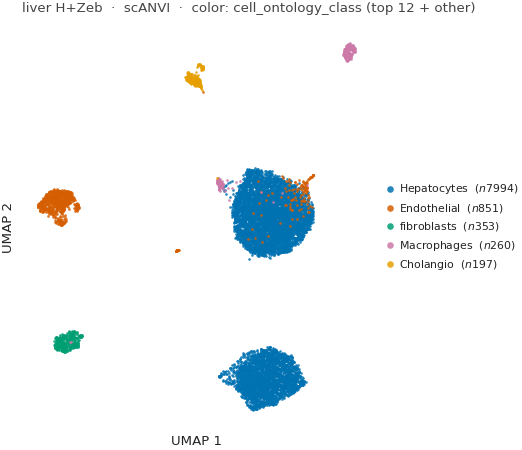

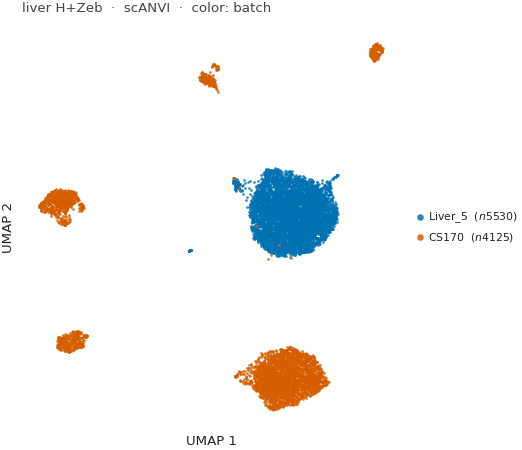


--- liver H+Zeb  ·  Harmony  (9655 cells, z→UMAP cached) ---


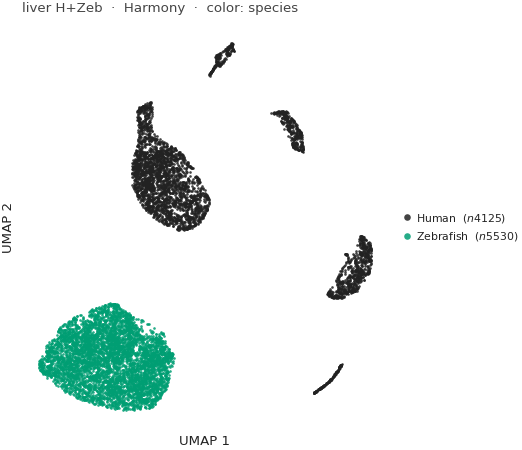

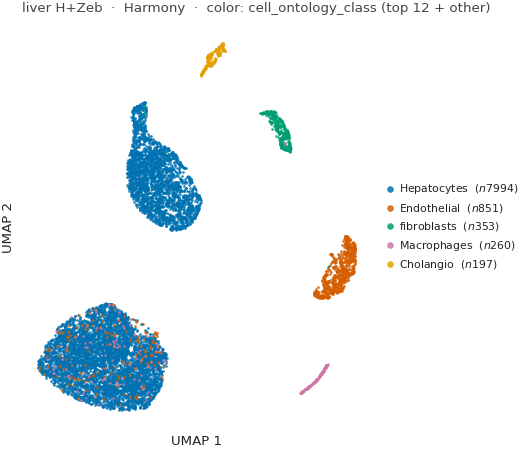

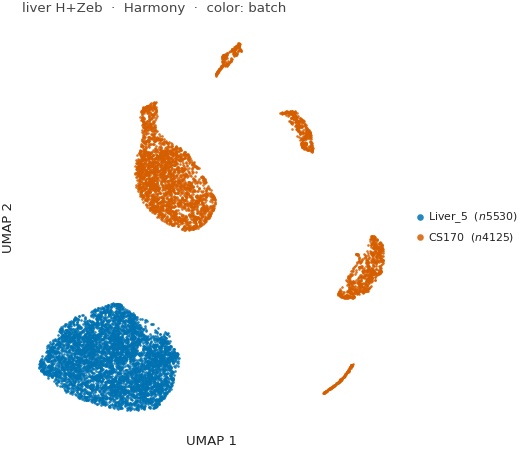


--- liver H+Zeb  ·  sysVI  (9655 cells, z→UMAP cached) ---


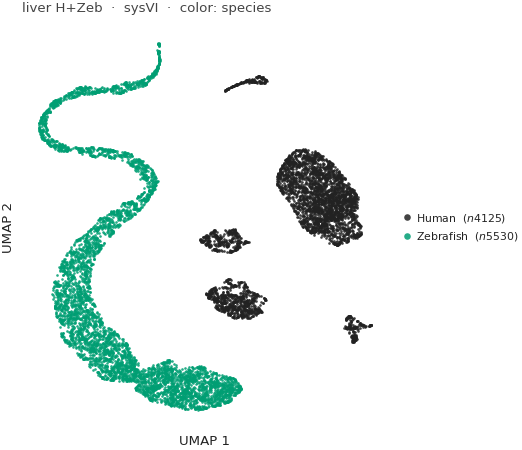

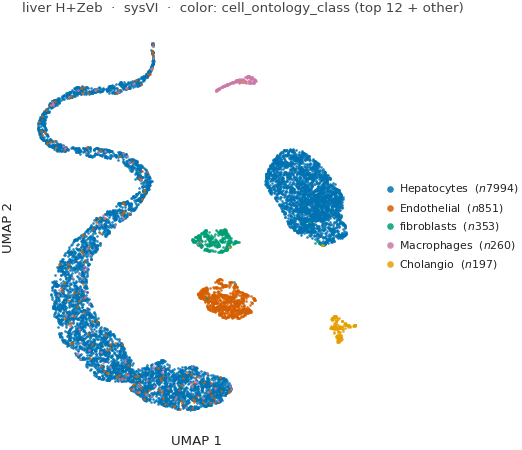

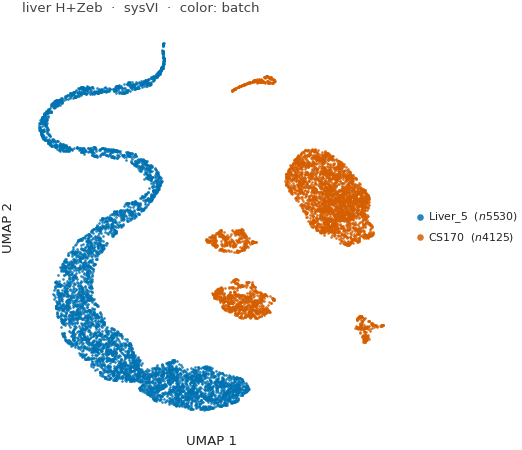


--- liver H+Zeb  ·  Chimera  (9655 cells, z→UMAP cached) ---


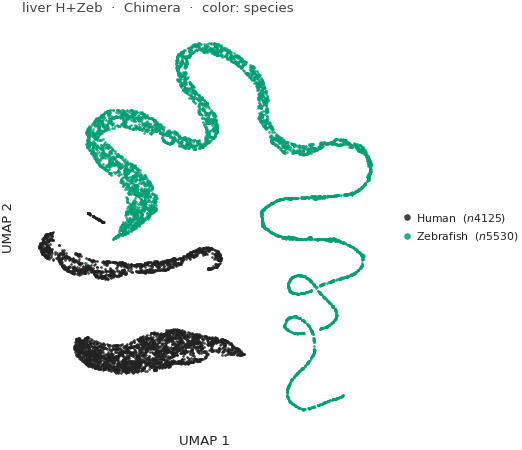

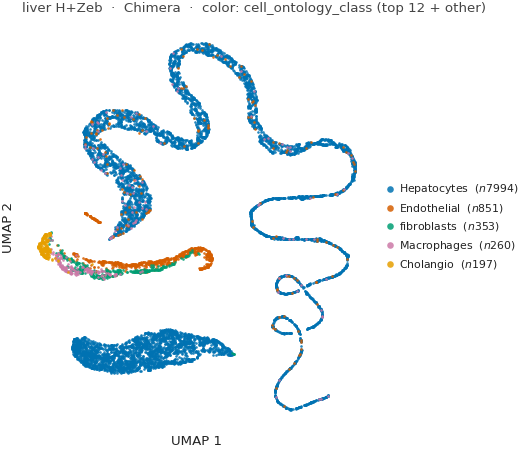

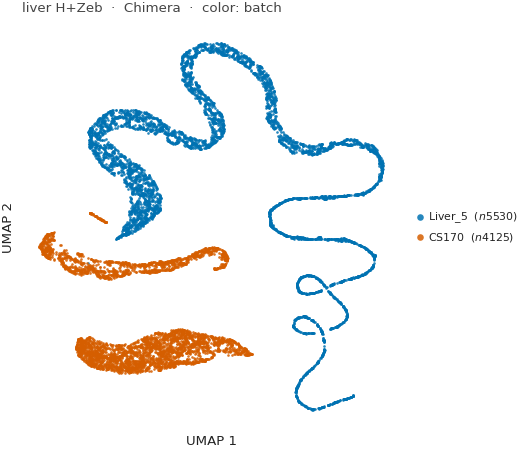


=== liver 4-sp ===

--- liver 4-sp  ·  PCA  (22104 cells, z→UMAP cached) ---


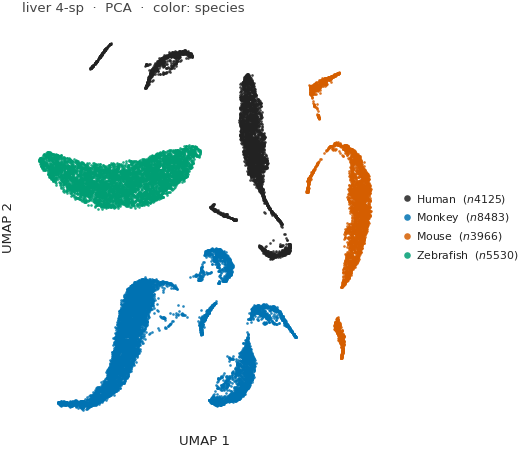

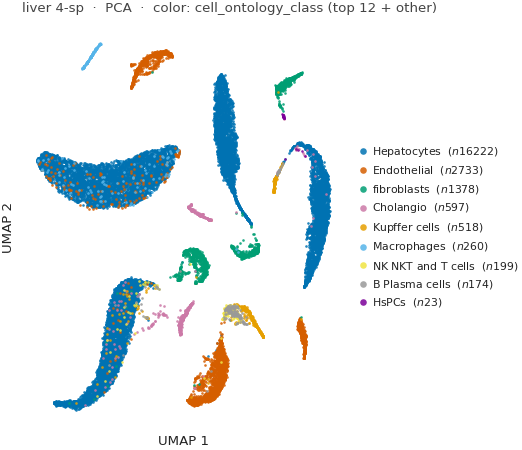

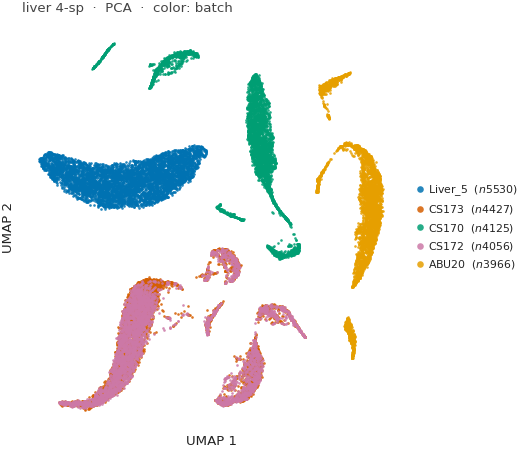


--- liver 4-sp  ·  scVI-sp  (22104 cells, z→UMAP cached) ---


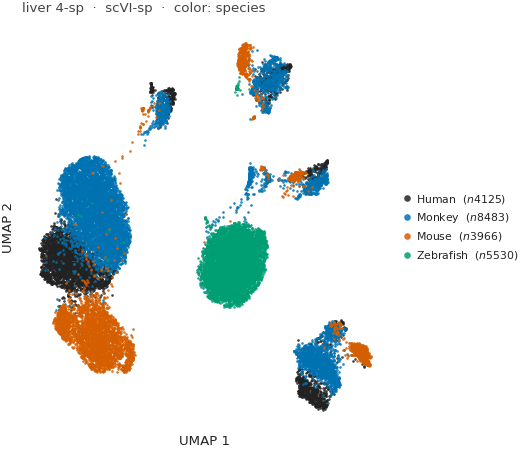

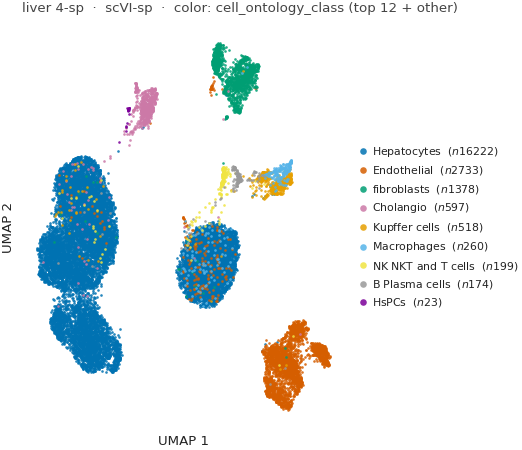

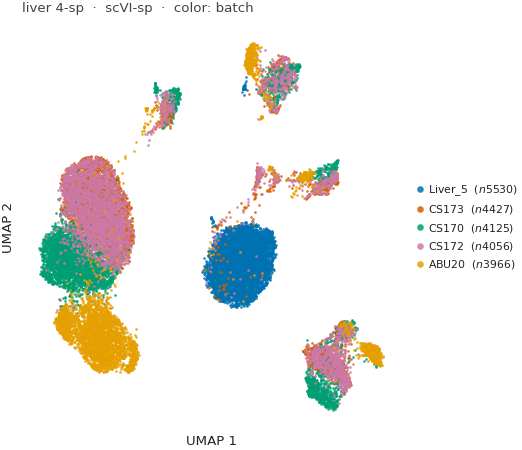


--- liver 4-sp  ·  scVI-donor  (22104 cells, z→UMAP cached) ---


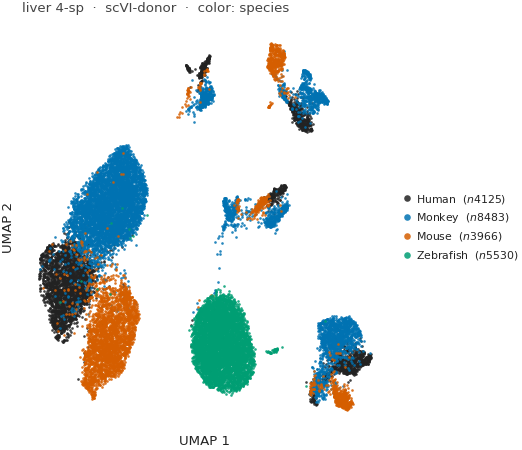

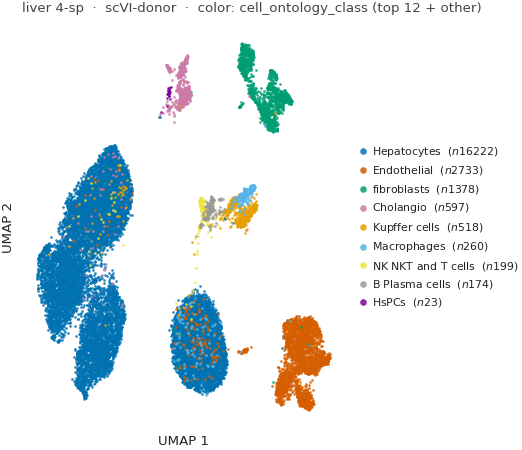

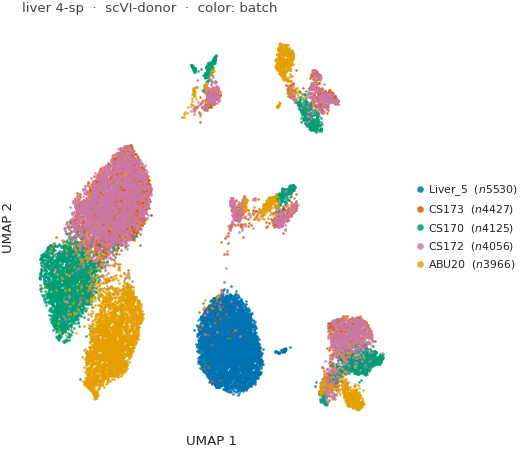


--- liver 4-sp  ·  scANVI  (22104 cells, z→UMAP cached) ---


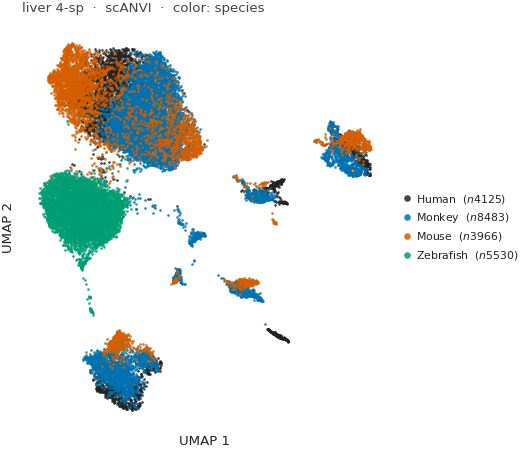

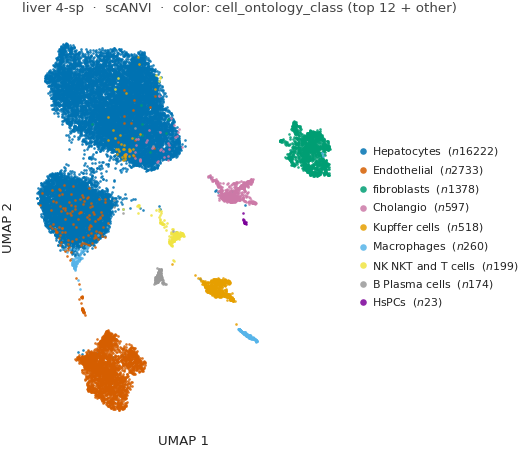

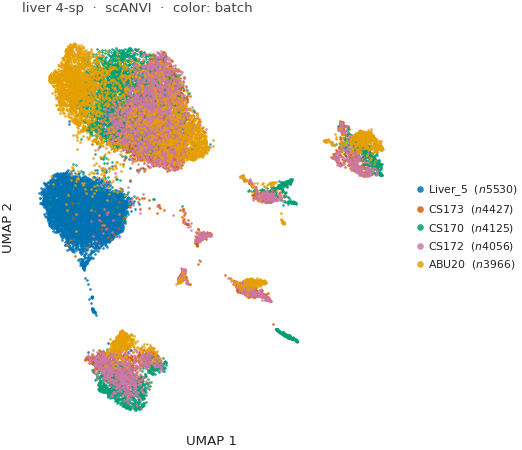


--- liver 4-sp  ·  Harmony  (22104 cells, z→UMAP cached) ---


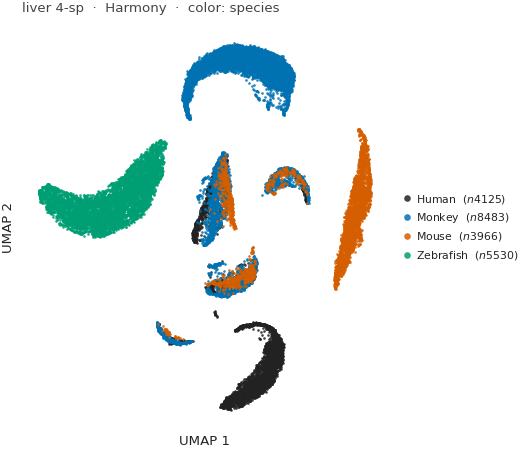

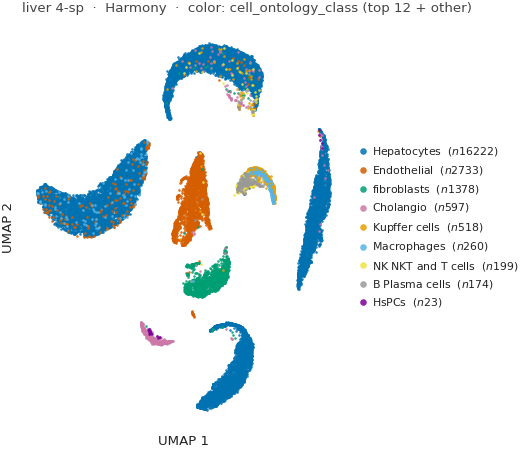

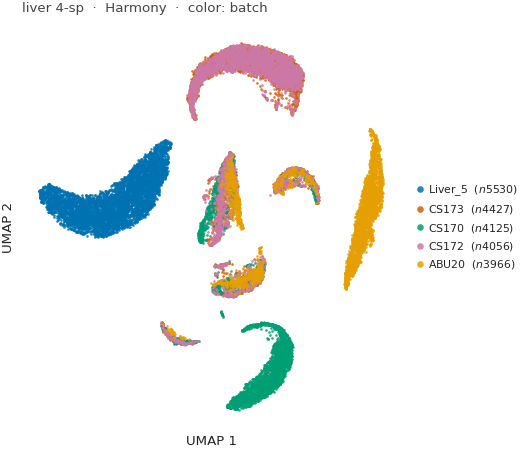


--- liver 4-sp  ·  sysVI  (22104 cells, z→UMAP cached) ---


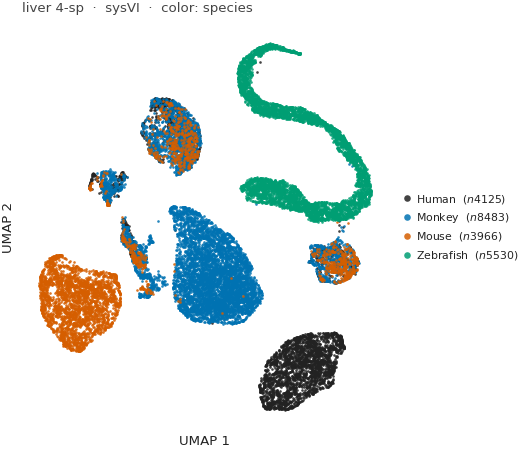

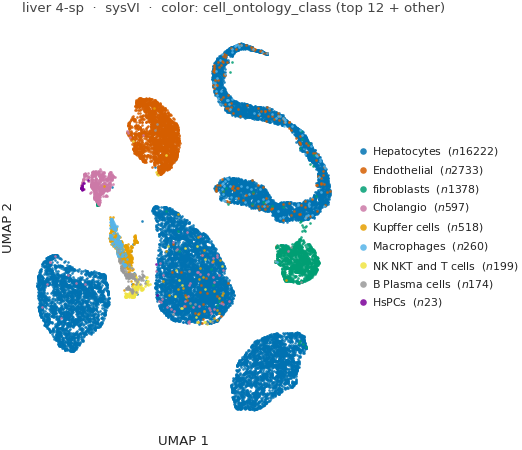

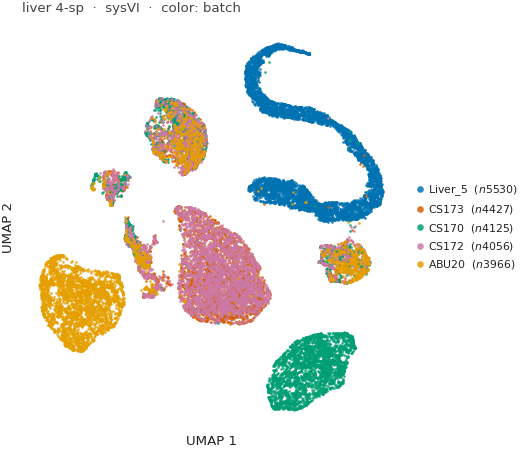


--- liver 4-sp  ·  Chimera  (22104 cells, z→UMAP cached) ---


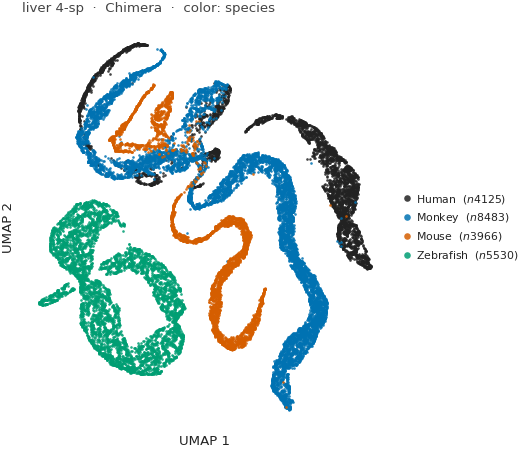

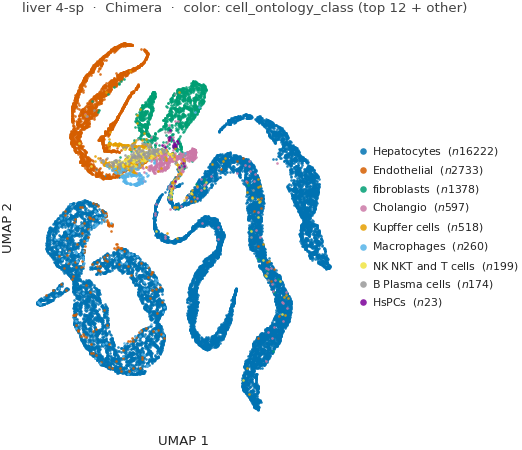

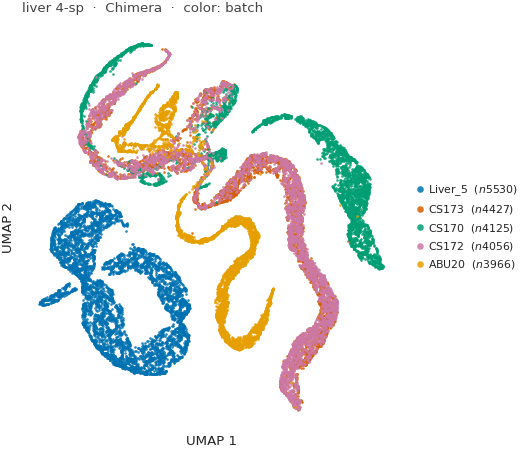


=== testis H+Mac ===

--- testis H+Mac  ·  PCA  (23593 cells, z→UMAP cached) ---


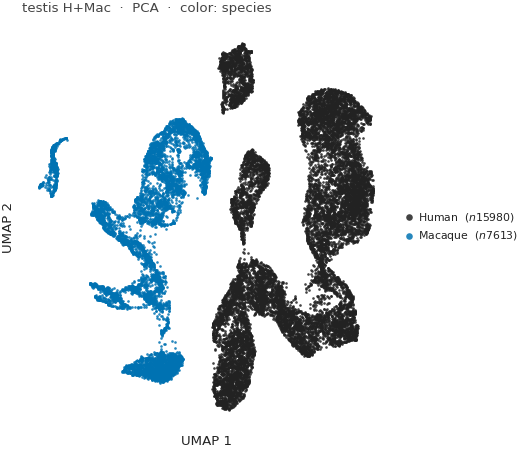

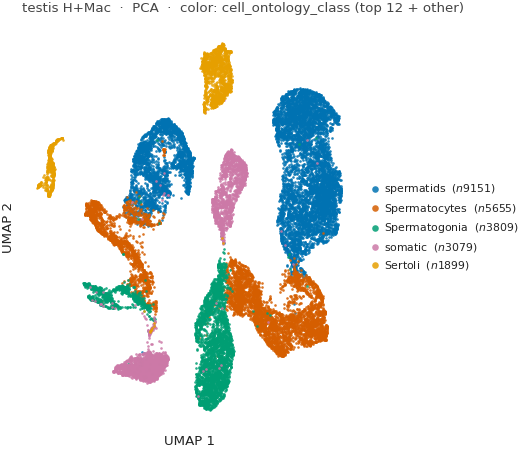

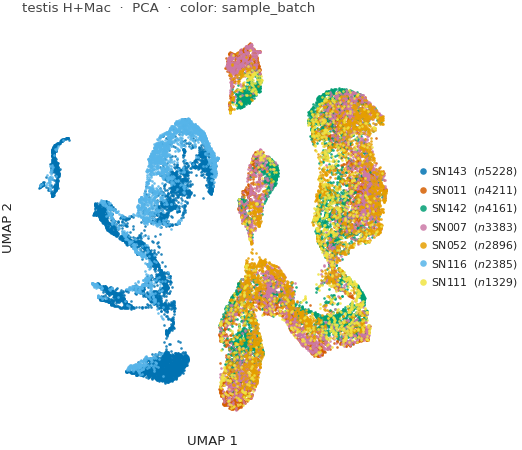


--- testis H+Mac  ·  scVI-sp  (23593 cells, z→UMAP cached) ---


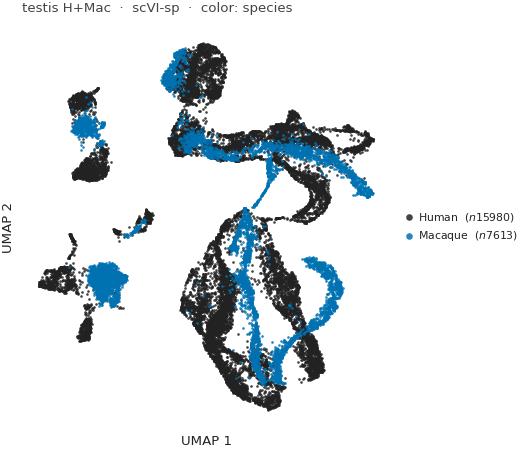

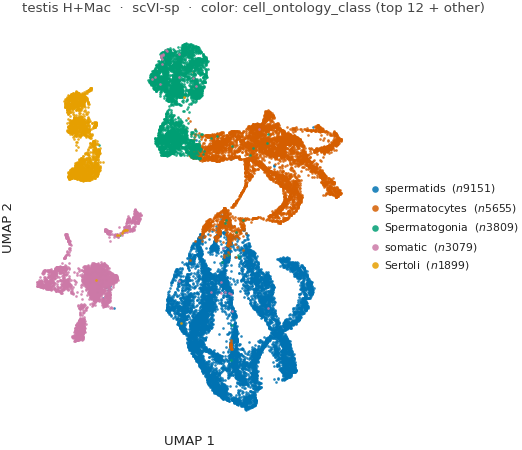

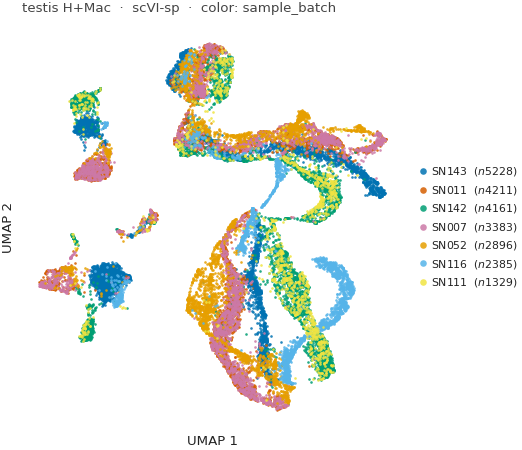


--- testis H+Mac  ·  scVI-donor  (23593 cells, z→UMAP cached) ---


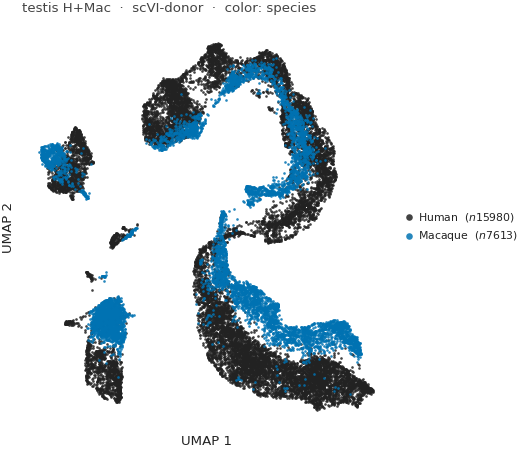

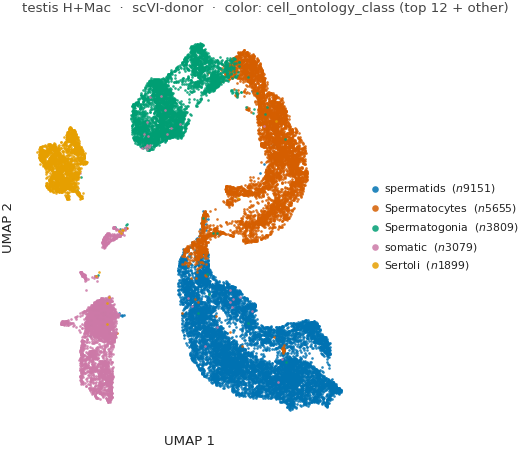

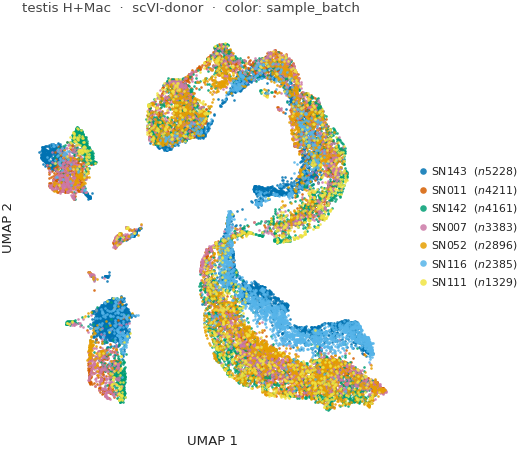


--- testis H+Mac  ·  scANVI  (23593 cells, z→UMAP cached) ---


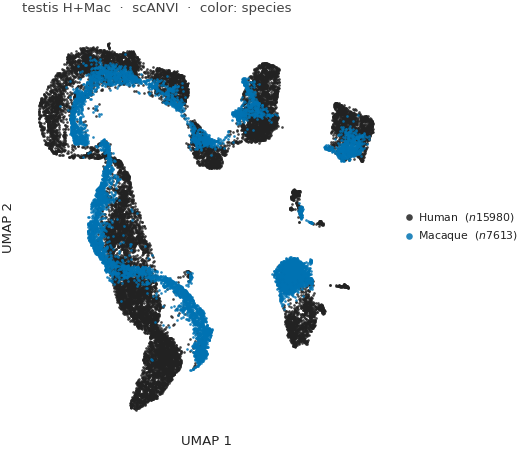

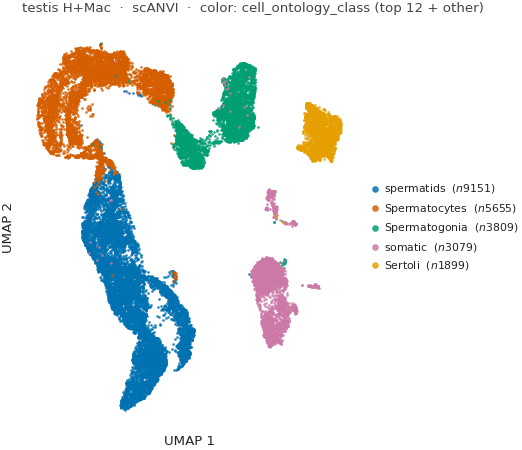

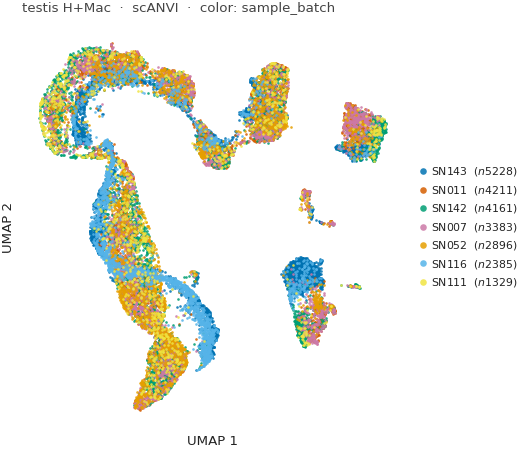


--- testis H+Mac  ·  Harmony  (23593 cells, z→UMAP cached) ---


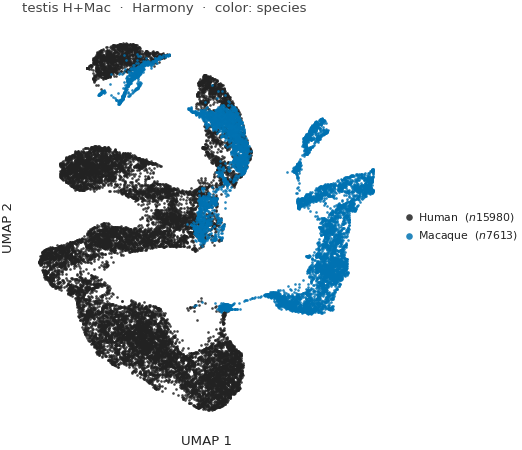

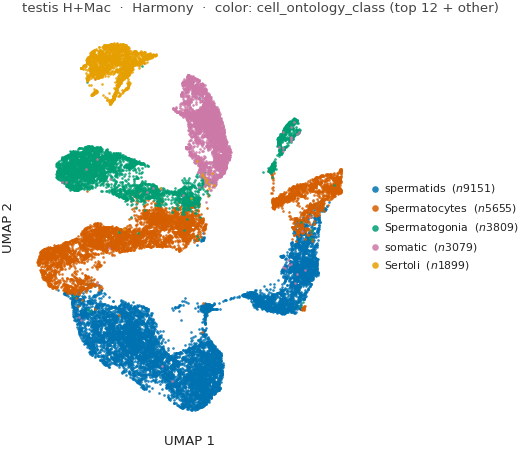

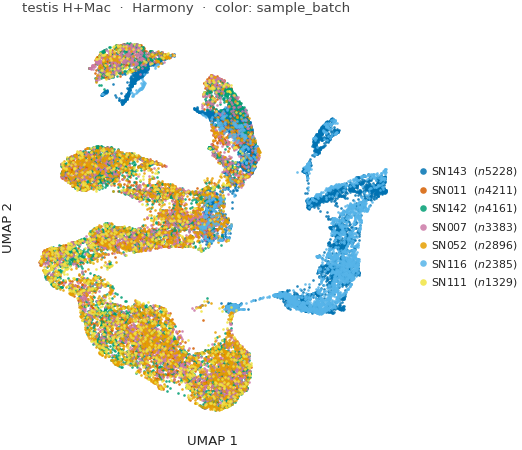


--- testis H+Mac  ·  sysVI  (23593 cells, z→UMAP cached) ---


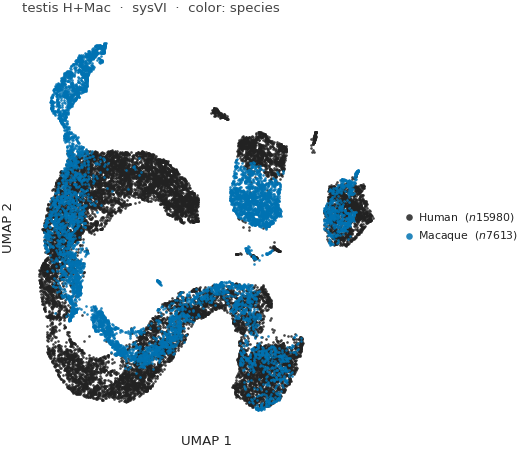

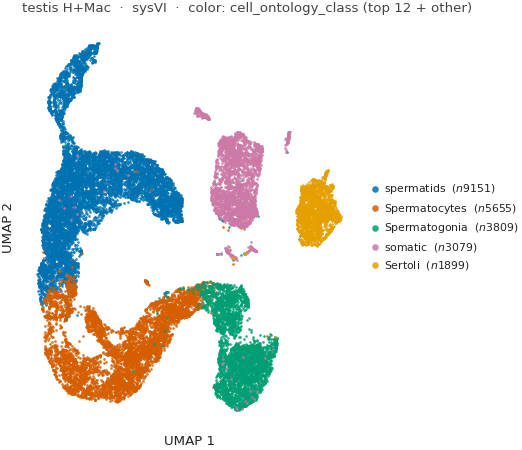

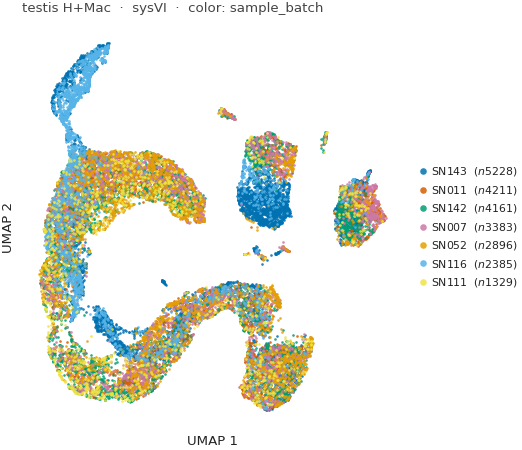


--- testis H+Mac  ·  Chimera  (23593 cells, z→UMAP cached) ---


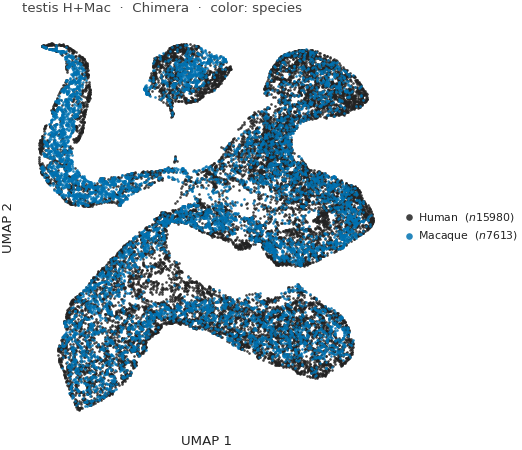

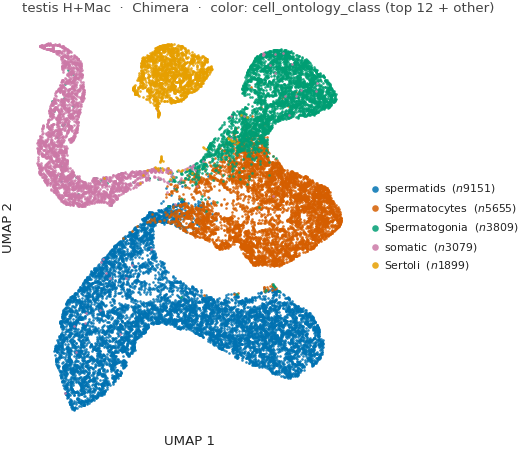

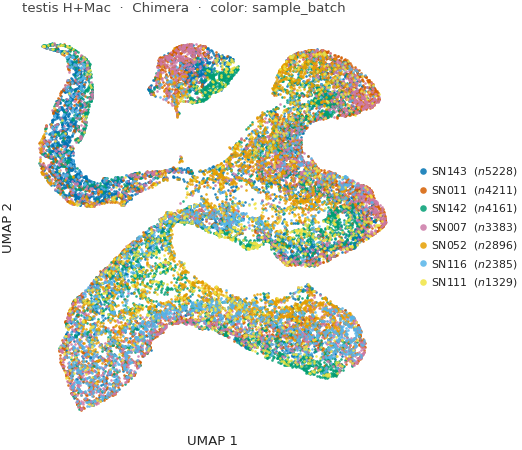


=== testis H+Mouse ===

--- testis H+Mouse  ·  PCA  (21241 cells, z→UMAP cached) ---


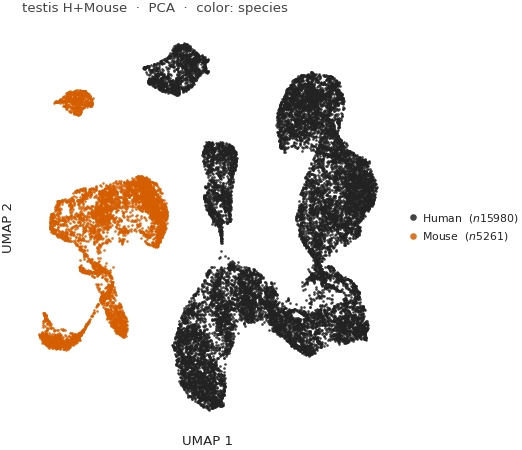

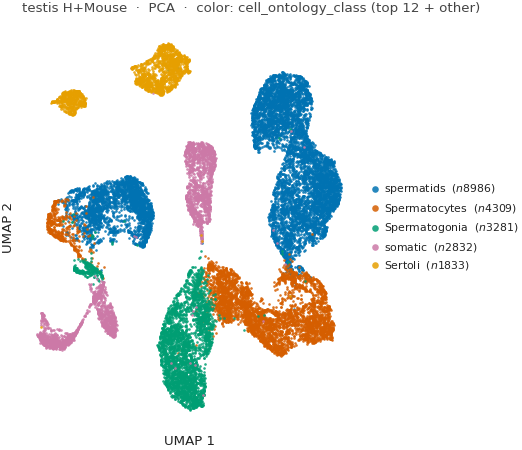

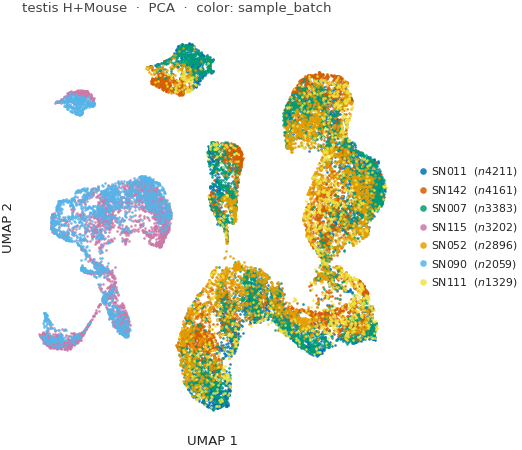


--- testis H+Mouse  ·  scVI-sp  (21241 cells, z→UMAP cached) ---


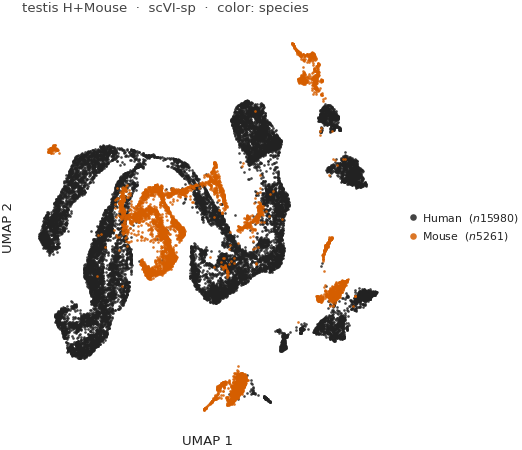

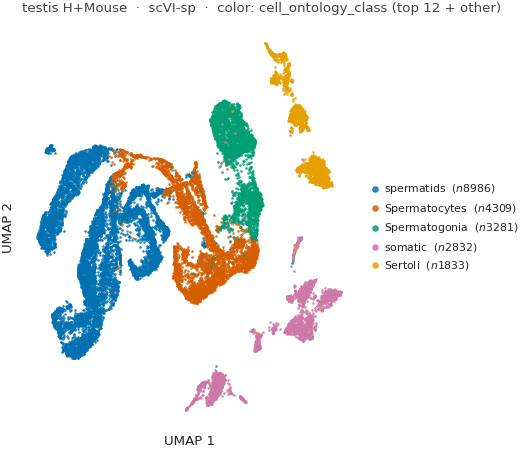

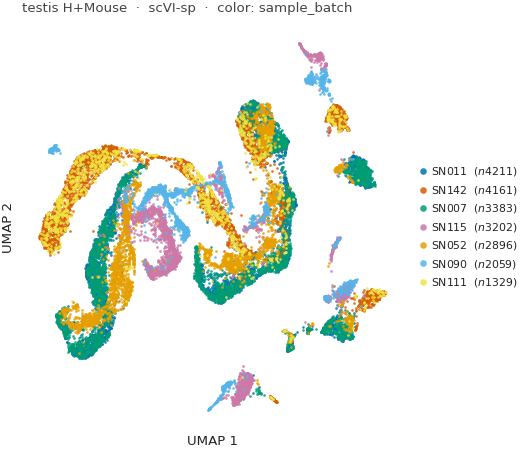


--- testis H+Mouse  ·  scVI-donor  (21241 cells, z→UMAP cached) ---


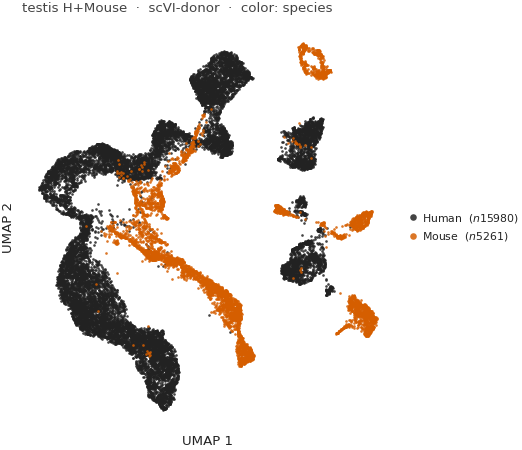

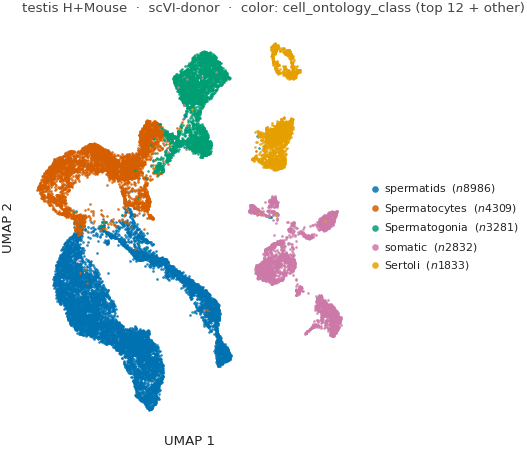

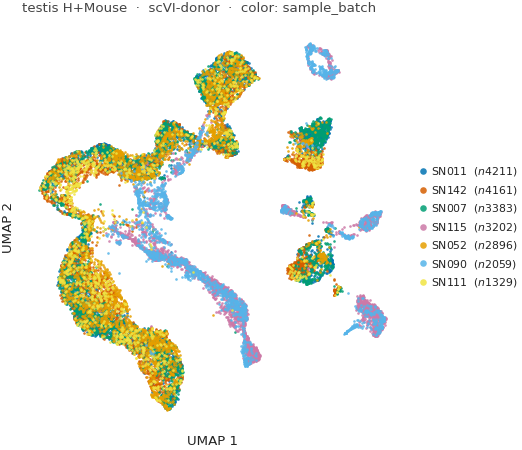


--- testis H+Mouse  ·  scANVI  (21241 cells, z→UMAP cached) ---


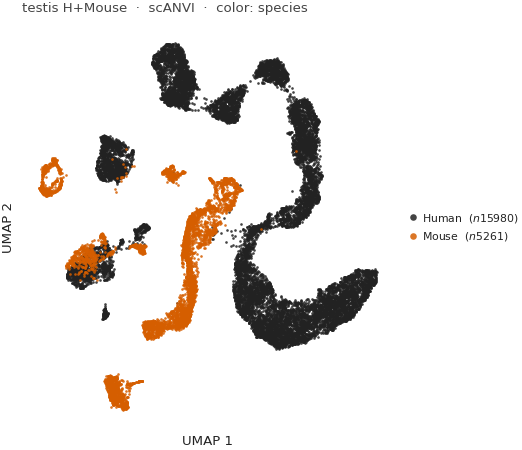

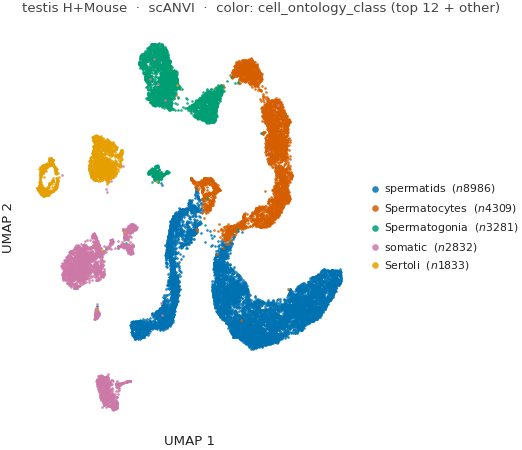

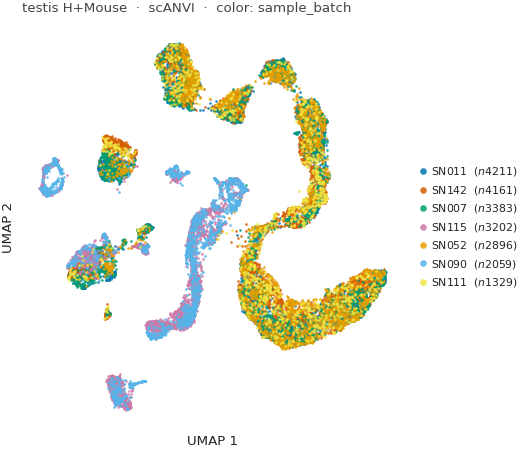


--- testis H+Mouse  ·  Harmony  (21241 cells, z→UMAP cached) ---


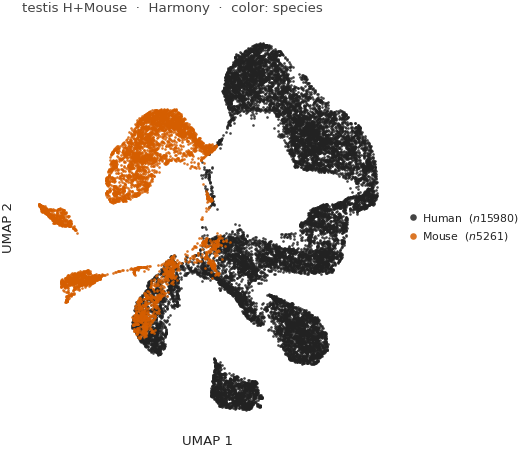

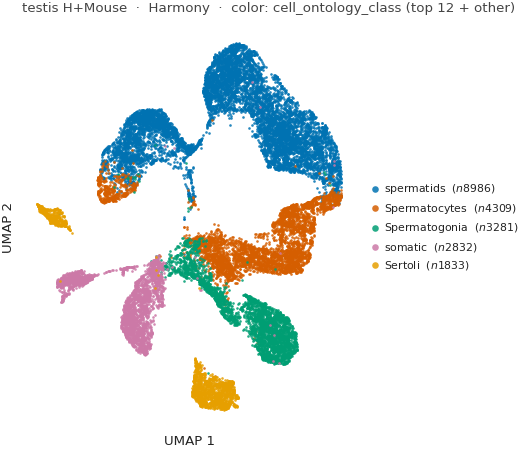

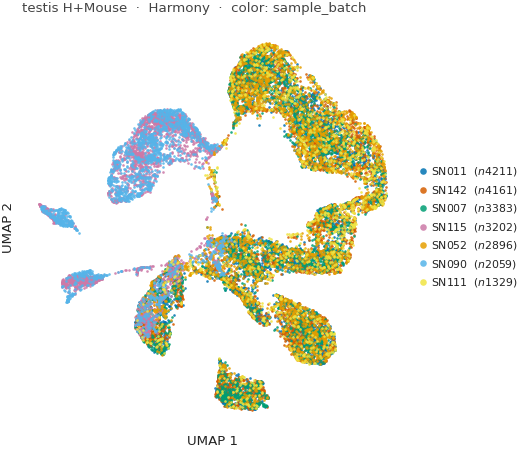


--- testis H+Mouse  ·  sysVI  (21241 cells, z→UMAP cached) ---


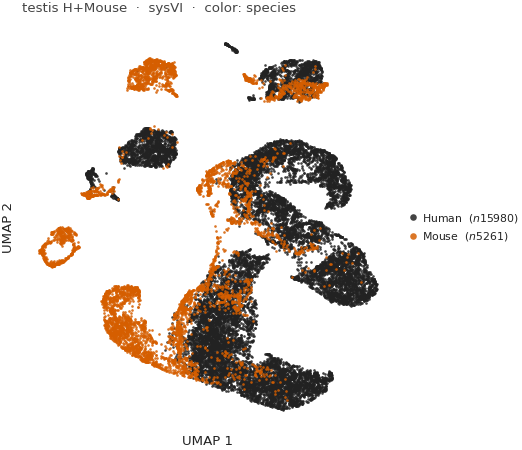

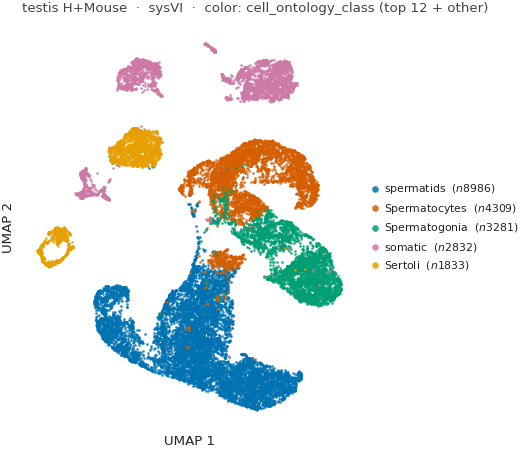

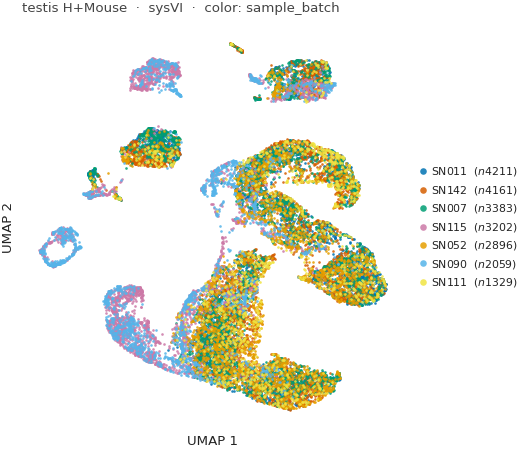


--- testis H+Mouse  ·  Chimera  (21241 cells, z→UMAP cached) ---


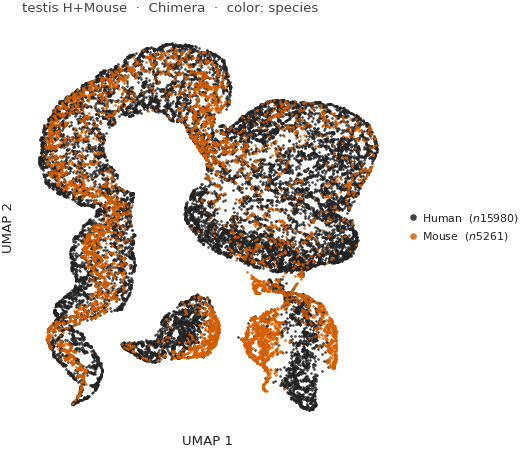

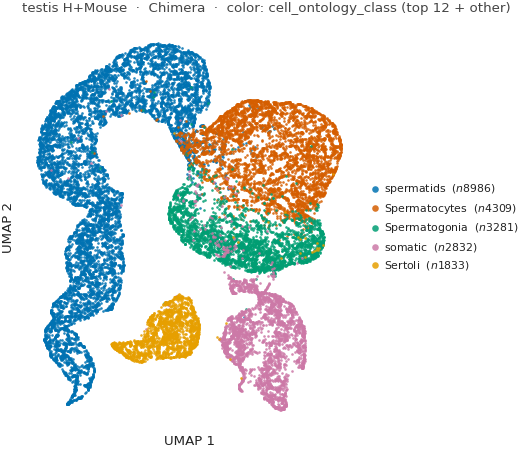

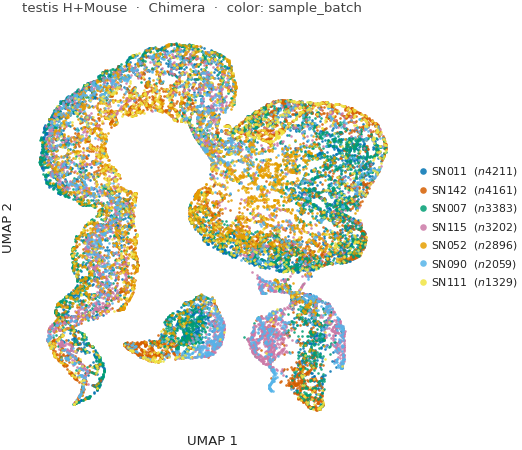


=== testis 3-sp ===

--- testis 3-sp  ·  PCA  (28854 cells, z→UMAP cached) ---


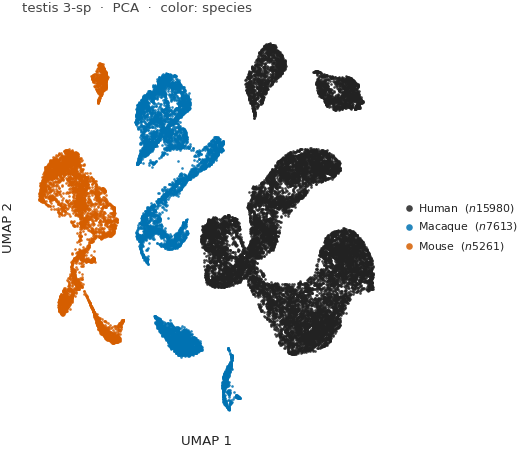

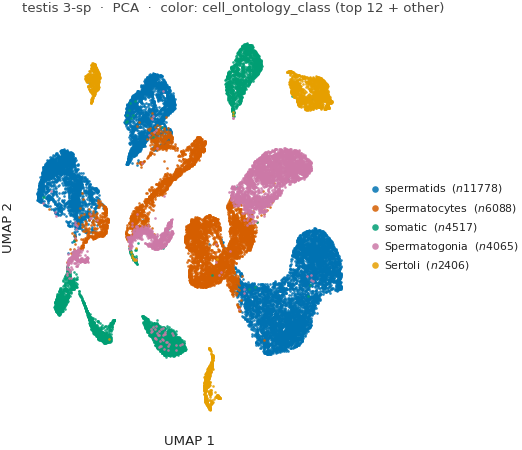

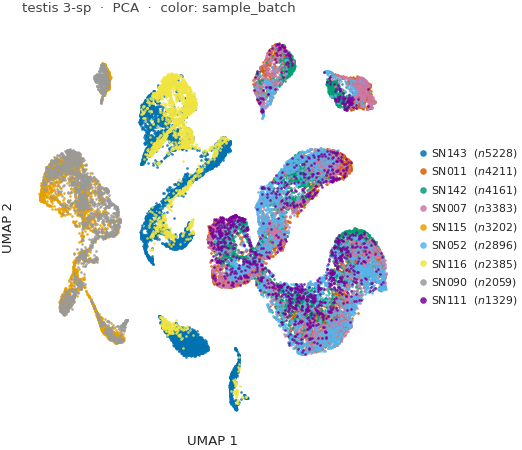


--- testis 3-sp  ·  scVI-sp  (28854 cells, z→UMAP cached) ---


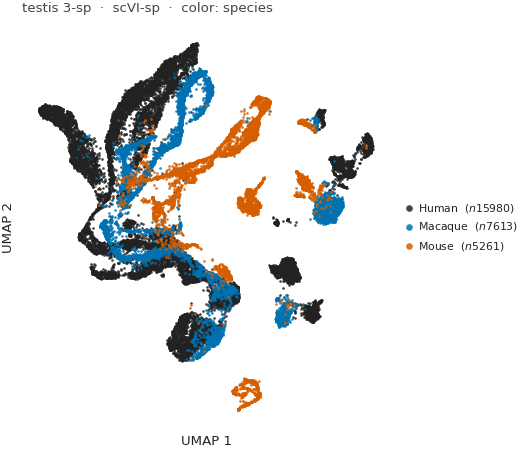

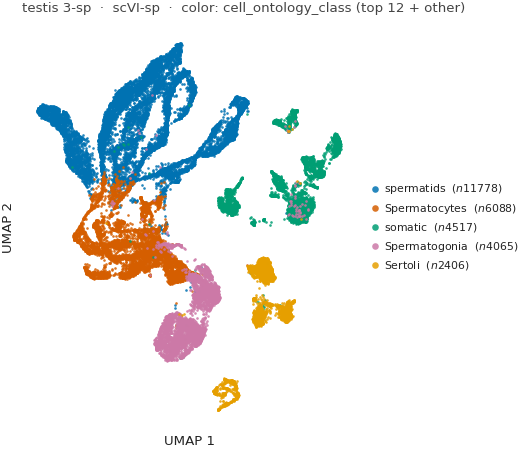

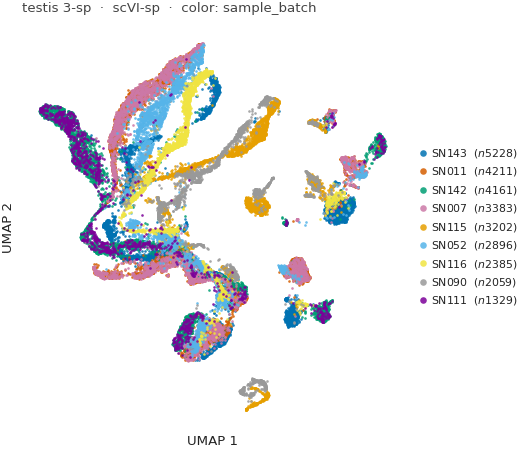


--- testis 3-sp  ·  scVI-donor  (28854 cells, z→UMAP cached) ---


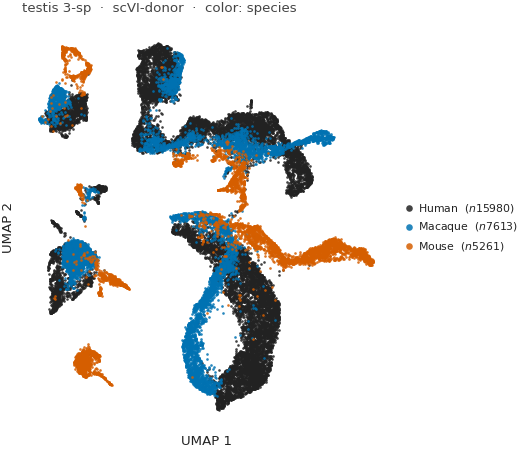

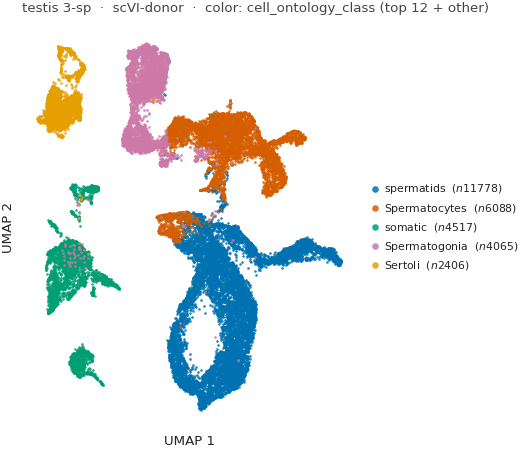

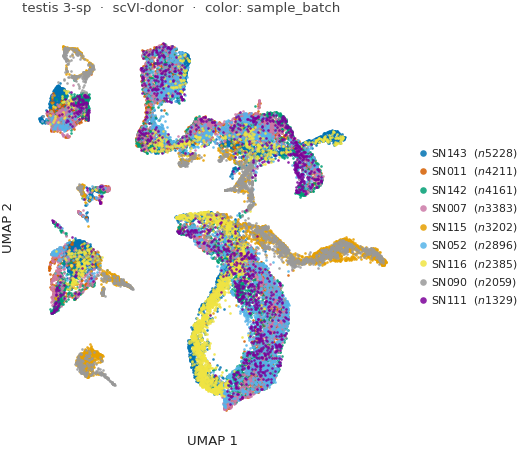


--- testis 3-sp  ·  scANVI  (28854 cells, z→UMAP cached) ---


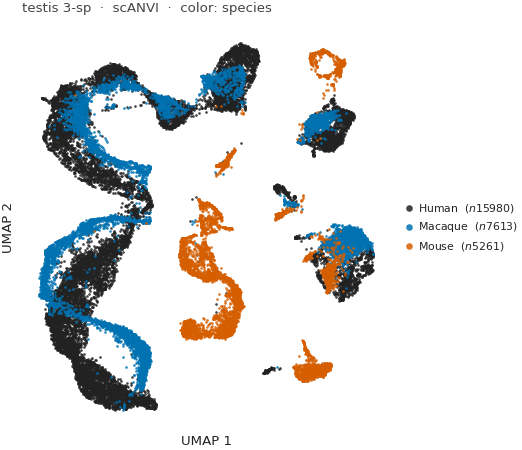

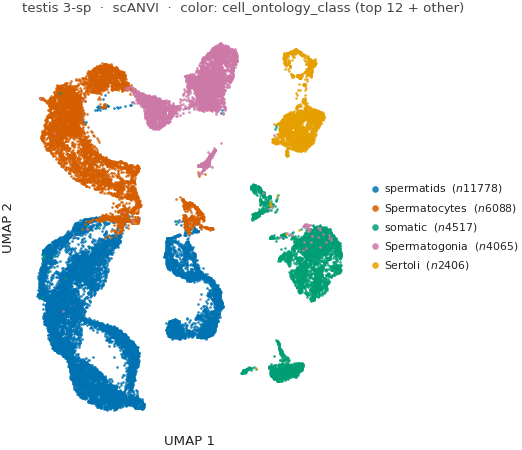

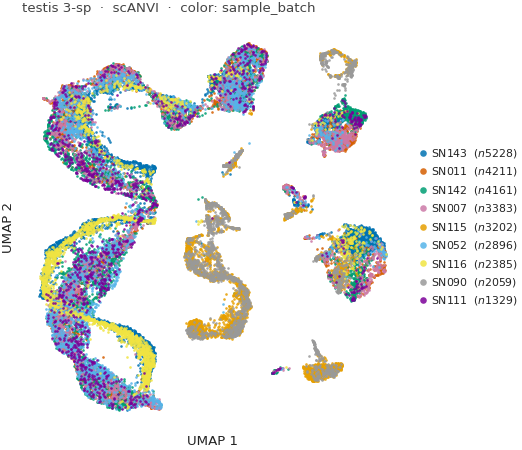


--- testis 3-sp  ·  Harmony  (28854 cells, z→UMAP cached) ---


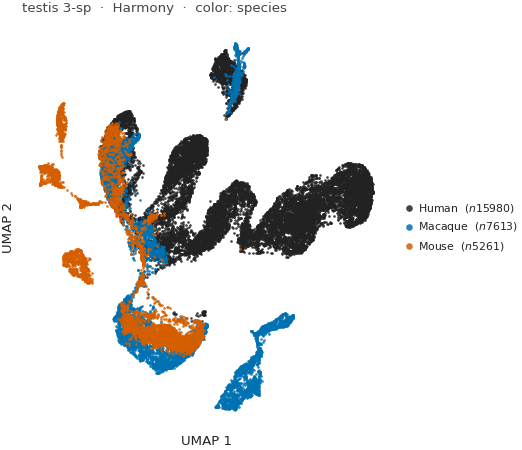

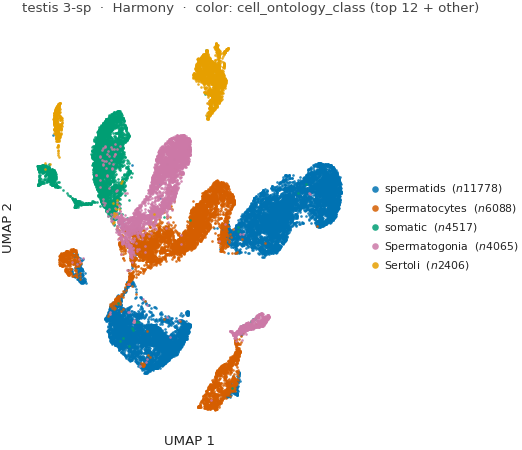

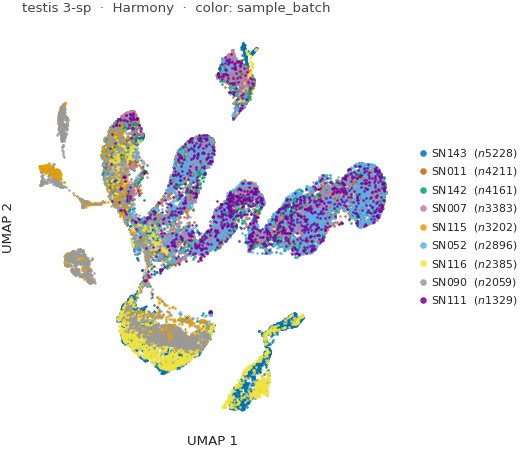


--- testis 3-sp  ·  sysVI  (28854 cells, z→UMAP cached) ---


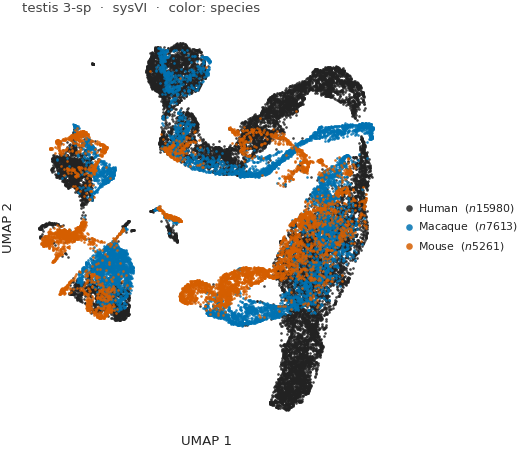

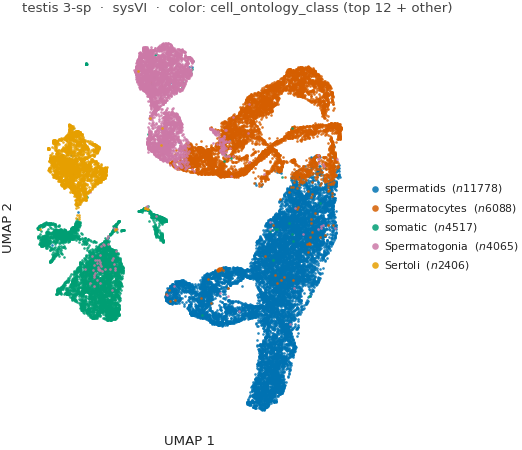

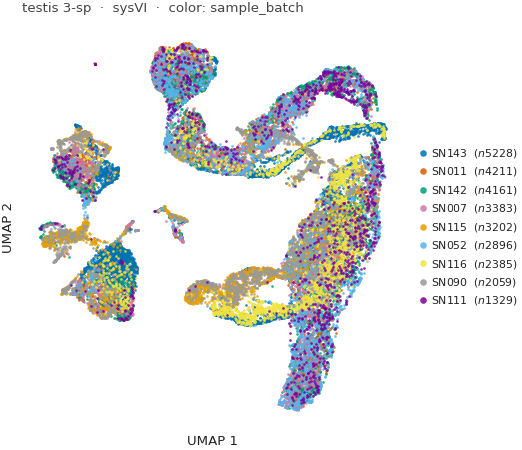


--- testis 3-sp  ·  Chimera  (28854 cells, z→UMAP cached) ---


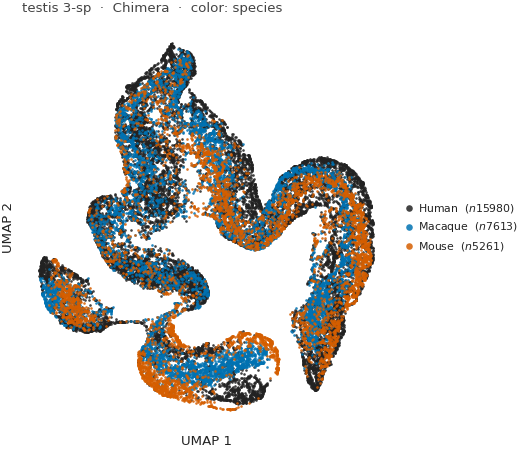

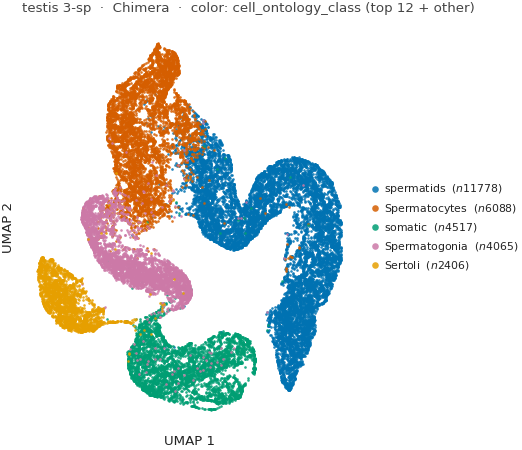

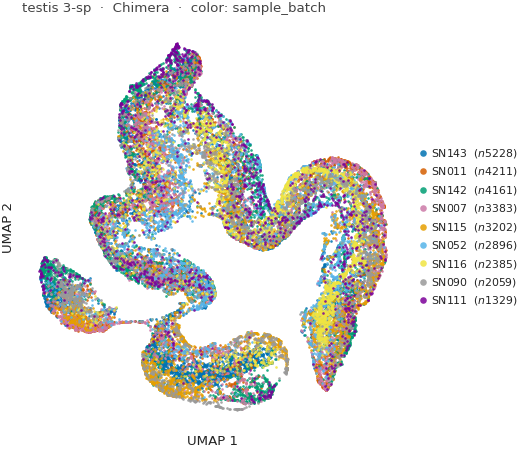

In [6]:
def render_pair(ds_key: str, model: str) -> None:
    '''Three single-panel UMAP figures for one (dataset, model) pair.'''
    if not READY[(ds_key, model)]:
        return
    info = DATASETS[ds_key]
    label = info["label"]
    slug = MODEL_SLUG[model]
    xy = UMAPS[(ds_key, model)]
    obs, ct_col = _read_obs(ds_key)
    bk_col = info["donor_batch_key"]
    n = xy.shape[0]
    print(f"\n--- {label}  ·  {model}  ({n} cells, z→UMAP cached) ---")

    # Species panel — fixed palette + evolutionary order.
    sp_vals = np.asarray(obs["species"].astype(str).values)
    sp_present = pd.Series(sp_vals).value_counts().index.tolist()
    sp_order = sorted(sp_present, key=fd.species_sort_key)
    sp_cmap = {s: fd.species_color(s) for s in sp_order}
    umap_panel(
        xy, sp_vals,
        title=f"{label}  ·  {model}  ·  color: species",
        save_name=f"A_{slug}_umap__species__{ds_key}",
        color_map=sp_cmap, category_order=sp_order,
        legend_ncol=1,
    )

    # Cell-type panel — top-N by count, then "other" pooled.
    ct_vals = np.asarray(obs[ct_col].astype(str).values)
    ct_counts = pd.Series(ct_vals).value_counts()
    TOP = 12
    top_cts = list(ct_counts.head(TOP).index)
    ct_collapsed = np.where(np.isin(ct_vals, top_cts), ct_vals, "other")
    ct_order = top_cts + (["other"] if (ct_collapsed == "other").any() else [])
    ct_cmap = {c: PALETTE_BIG[i % len(PALETTE_BIG)] for i, c in enumerate(top_cts)}
    if "other" in ct_order:
        ct_cmap["other"] = "#bbbbbb"
    umap_panel(
        xy, ct_collapsed,
        title=f"{label}  ·  {model}  ·  color: {ct_col} (top {TOP} + other)",
        save_name=f"A_{slug}_umap__celltype__{ds_key}",
        color_map=ct_cmap, category_order=ct_order,
        legend_ncol=1,
    )

    # Batch panel — donor batch = `batch` (liver) or `sample_batch` (testis).
    bk_vals = np.asarray(obs[bk_col].astype(str).values)
    bk_counts = pd.Series(bk_vals).value_counts()
    bk_order = list(bk_counts.index)
    bk_cmap = {b: PALETTE_BIG[i % len(PALETTE_BIG)] for i, b in enumerate(bk_order)}
    umap_panel(
        xy, bk_vals,
        title=f"{label}  ·  {model}  ·  color: {bk_col}",
        save_name=f"A_{slug}_umap__batch__{ds_key}",
        color_map=bk_cmap, category_order=bk_order,
        legend_ncol=1,
    )


for k in DATASET_ORDER:
    print(f"\n=== {DATASETS[k]['label']} ===")
    for m in MODEL_ORDER:
        render_pair(k, m)


*Read the panels.* On each `(dataset, model)` row, the species
panel and the cell-type panel together summarise the
integration scorecard that `07_baselines_master.ipynb`
quantifies: well-mixed species + well-separated cell-type
clusters is the architectural goal. Visual reading order:
*PCA → scVI-sp → scVI-donor → scANVI → Harmony → sysVI →
Chimera* — across that sequence the species panel should
progress from highly stratified-by-species (PCA, no integration)
to well-mixed (Chimera and the strongest baselines), while the
cell-type panel should remain or become more cleanly clustered.
The batch panel is the confound check — donor structure that
out-shouts species or cell-type structure would indicate
integration is happening on the wrong axis.

Two known characteristics of the registry are visible:

1. **Liver H+Zebrafish** has the largest evolutionary distance
   in the 2-species liver panel and shows the noisiest mixing —
   expected, and consistent with `workflow-best.md` row "very"
   diverged.
2. **Testis 3-species** has only two cell types shared across
   all three species (the rest are species-specific), so the
   cell-type panel will show a few large clusters dominated by
   one species' annotation while the rest are sparse — read the
   panel together with the registry's "structural" note.

*To re-style without recomputing UMAP:* edit `umap_panel(...)`
or `render_pair(...)` above and re-run only the §A code cell.
The kNN + UMAP step is gated by `compute_or_load_umap` and will
short-circuit to the cached `.npy` files. To recompute one
pair (e.g. after changing `n_neighbors`), delete that cache
file or call `compute_or_load_umap(ds_key, model, force=True)`.


In [7]:
written = sorted(FIG_DIR.glob("*.pdf"))
print(f"\n{len(written)} PDF figures in {FIG_DIR}:")
for p in written:
    print(f"  {p.name:60s} {p.stat().st_size/1024:6.1f} KB")



147 PDF figures in /Users/kemalinecik/git_nosync/master_chimera/chimera/notebooks/figures/chimera_umap:
  a_chimera_umap__batch__panc_4sp.pdf                           270.1 KB
  a_chimera_umap__batch__panc_hmonkey.pdf                       448.6 KB
  a_chimera_umap__batch__panc_hmouse.pdf                        157.3 KB
  a_chimera_umap__batch__panc_hzeb.pdf                          104.7 KB
  a_chimera_umap__batch__test_3sp.pdf                           767.4 KB
  a_chimera_umap__batch__test_hmac.pdf                          831.7 KB
  a_chimera_umap__batch__test_hmouse.pdf                        774.1 KB
  a_chimera_umap__celltype__panc_4sp.pdf                        206.2 KB
  a_chimera_umap__celltype__panc_hmonkey.pdf                    209.2 KB
  a_chimera_umap__celltype__panc_hmouse.pdf                     130.2 KB
  a_chimera_umap__celltype__panc_hzeb.pdf                       140.9 KB
  a_chimera_umap__celltype__test_3sp.pdf                        241.8 KB
  a_chimera_umap__c